In [1]:
!pip -q install lifelines

import re, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test
from IPython.display import display

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from google.colab import files

COHORT = "Burgmaier"            # First reproduce Burgmaier's four-class curves
PLOT_END_YEAR = 18              # Same x-axis limit as AA709_1837.ipynb
OUTPUT_DIR = Path('/content/PKHD1_four_class_figures')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATHS = {
    'Burgmaier': Path('/content/Burgmaier_Genotype_Phenotype_Replication - Burgmaier_S3_Source (2).csv'),
    'NephVar': Path('/content/NephVar Database - PKHD1 (5).csv'),
}

if not CSV_PATHS[COHORT].is_file():
    print(f'Upload this file: {CSV_PATHS[COHORT].name}')
    files.upload()

assert CSV_PATHS[COHORT].is_file(), f'Missing input CSV at {CSV_PATHS[COHORT]}'
for name, path in CSV_PATHS.items():
    print(f'{name:10s}: {path} ({"found" if path.is_file() else "not uploaded"})')


Burgmaier : /content/Burgmaier_Genotype_Phenotype_Replication - Burgmaier_S3_Source (2).csv (found)
NephVar   : /content/NephVar Database - PKHD1 (5).csv (found)


# ARegPKD

In [3]:
REGIONS = [
    ('AA2625–4074', 'Mis2625-4074', '#e74c3c'),
    ('AA1838–2624', 'Mis1838-2624', '#27ae60'),
    ('AA1–708',      'Mis1-708',      '#2980b9'),
    ('AA709–1837',   'Mis709-1837',   '#8e44ad'),
]
GROUP_ORDER = [x[0] for x in REGIONS]
COLORS = dict((label,color) for label,_,color in REGIONS)


def extract_age(value):
    """Only read a number at the start; '-' and unreported ages => NaN."""
    m = re.match(r'^\s*([+-]?(?:\d+(?:\.\d*)?|\.\d+))', str(value))
    return float(m.group(1)) if m else np.nan


def column_starting(df, prefix):
    xs = [c for c in df if c.lower().startswith(prefix.lower())]
    if len(xs) != 1:
        raise ValueError(f'Expected one column starting {prefix!r}, got {xs}')
    return xs[0]


def load_cohort(name):
    df = pd.read_csv(CSV_PATHS[name], dtype=str)
    # Exclude non-patient notes, empty rows, and trailing spreadsheet summaries.
    df = df.loc[df['Predicted protein change'].notna()].copy()
    df['source_row'] = df.index + 2  # original spreadsheet row (1-based, incl. header)
    norm = df['Functional class'].fillna('').str.replace(r'\s+', '', regex=True)
    df['group'] = pd.Series(pd.NA,index=df.index,dtype='object')
    for label,region,_ in REGIONS:
        allowed = {f'Null/{region}',f'{region}/Null',f'{region}/{region}'}
        df.loc[norm.isin(allowed),'group'] = label

    df['fu_raw'] = df[column_starting(df,'Last follow-')]
    df['fu'] = df['fu_raw'].map(extract_age)
    df['termination'] = df['fu_raw'].fillna('').str.contains('termination|terminated',case=False,regex=True)
    raw_events = {
        'KRT': column_starting(df,'KRT ('),
        'Portal HTN': column_starting(df,'Portal HTN'),
        'Hepatic': next(c for c in df if 'hepatic compli' in c.lower()),
    }
    for key, col in raw_events.items():
        df[f'{key}_age'] = df[col].map(extract_age)
    df['cohort'] = name
    return df

D = load_cohort(COHORT)
FOUR = D[D['group'].notna()].copy()
print(f'{COHORT}: {len(D)} patient records; {len(FOUR)} in the four groups')
print('Excluded other/mixed classes:', len(D)-len(FOUR))
display(FOUR.groupby('group').size().reindex(GROUP_ORDER).rename('Patients (before survival filtering)').to_frame())

if COHORT == 'Burgmaier':
    expected = {'AA2625–4074':21,'AA1838–2624':22,'AA1–708':44,'AA709–1837':51}
    observed = FOUR['group'].value_counts().to_dict()
    assert observed == expected, f'Burgmaier group count mismatch: {observed}'

Burgmaier: 304 patient records; 138 in the four groups
Excluded other/mixed classes: 166


,Patients (before survival filtering)
group,
AA2625–4074,21
AA1838–2624,22
AA1–708,44
AA709–1837,51


In [4]:
ENDPOINTS = [
    ('KRT', 'Patients without KRT','km_krt'),
    ('Portal HTN','Patients without portal hypertension','km_portal_htn'),
    ('Hepatic','Patients without substantial\nhepatic complication' if COHORT=='Burgmaier' else
     'Patients without documented\nhepatic involvement','km_hepatic'),
]

def survival_data(raw, endpoint):
    df = raw.copy()
    event_age = df[f'{endpoint}_age'].astype(float)
    df['event'] = event_age.notna().astype(int)
    df['duration'] = np.where(df['event'] == 1, event_age, df['fu'])
    df.loc[(df['event'] == 0) & (df['duration'] <= 0),'duration'] = np.nan
    df.loc[(df['event'] == 1) & (df['duration'] <= 0),'duration'] = 0.001
    df.loc[df['termination'],'duration'] = np.nan
    return df.loc[df['group'].notna() & df['duration'].notna()].copy()

SURVIVAL = {name:survival_data(FOUR,name) for name,_,_ in ENDPOINTS}
for endpoint,_,_ in ENDPOINTS:
    v = SURVIVAL[endpoint]
    print(f'{endpoint}: KM n={len(v)}; events={int(v.event.sum())}; censored={int((1-v.event).sum())}')
    conflict = v[(v.event==1)&(v.fu.notna())&(v[f'{endpoint}_age'] > v.fu+1e-9)]
    if len(conflict):
        print('  REVIEW: event age after last follow-up (not auto-corrected):')
        display(conflict[['source_row','group',f'{endpoint}_age','fu','Predicted protein change']])

KRT: KM n=137; events=31; censored=106
  REVIEW: event age after last follow-up (not auto-corrected):


,source_row,group,KRT_age,fu,Predicted protein change
42,44,AA2625–4074,1.45,0.5,p.Leu1966Thrfs*4; p.His3124Tyr


Portal HTN: KM n=137; events=58; censored=79
  REVIEW: event age after last follow-up (not auto-corrected):


,source_row,group,Portal HTN_age,fu,Predicted protein change
20,22,AA1–708,9.47,9.42,p.Leu115Serfs*8; p.Ile222Val
141,143,AA1–708,14.05,14.00,p.Thr36Met; p.Thr36Met
152,154,AA1–708,1.09,1.08,p.Thr36Met; p.?
177,179,AA2625–4074,6.38,6.33,p.Arg2840Cys; p.Arg2840Cys
186,188,AA2625–4074,2.19,2.17,p.Gly3532Arg; p.Gly3532Arg


Hepatic: KM n=137; events=17; censored=120


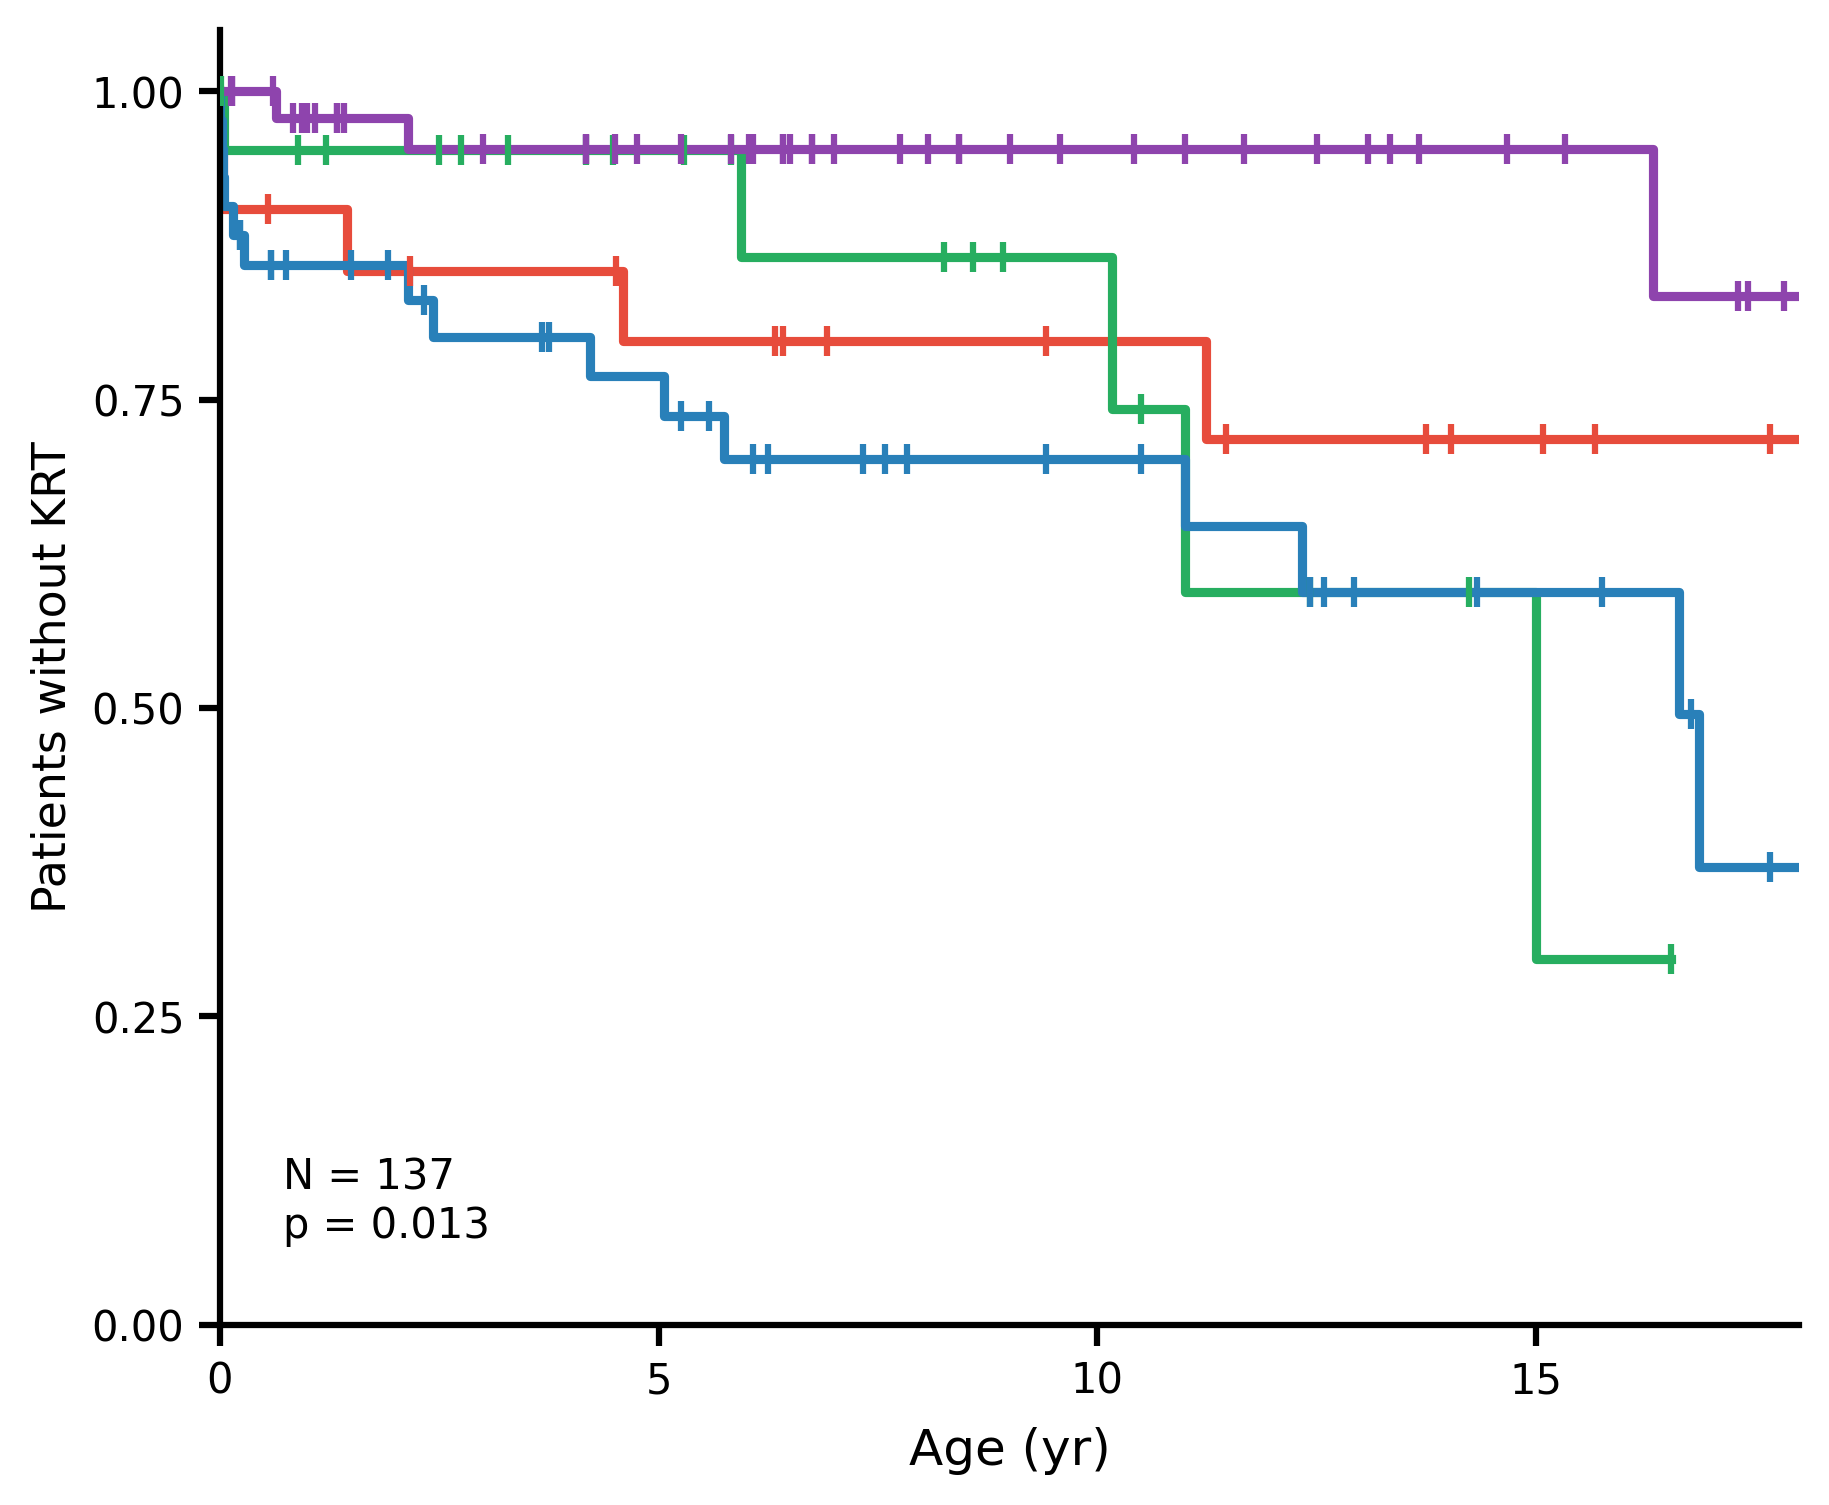


Burgmaier · KRT · n=137, events=31
Overall four-group log-rank: chi²=10.7161, p = 0.013
Saved: /content/PKHD1_four_class_figures/km_krt_burgmaier.png


,Group 1,Group 2,Log-rank p (raw),Holm-adjusted p
0,AA2625–4074,AA1838–2624,0.611958,1.000000
1,AA2625–4074,AA1–708,0.348415,1.000000
2,AA2625–4074,AA709–1837,0.080763,0.323053
3,AA1838–2624,AA1–708,0.630811,1.000000
4,AA1838–2624,AA709–1837,0.012779,0.063897
5,AA1–708,AA709–1837,0.000918,0.005508


Number at risk (actual KM-eligible patients):


,Group,N,Events,At risk 0y,At risk 5y,At risk 10y,At risk 15y
0,AA2625–4074,21,6,21,14,10,6
1,AA1838–2624,22,5,22,13,7,2
2,AA1–708,43,16,43,24,14,7
3,AA709–1837,51,4,51,33,17,9


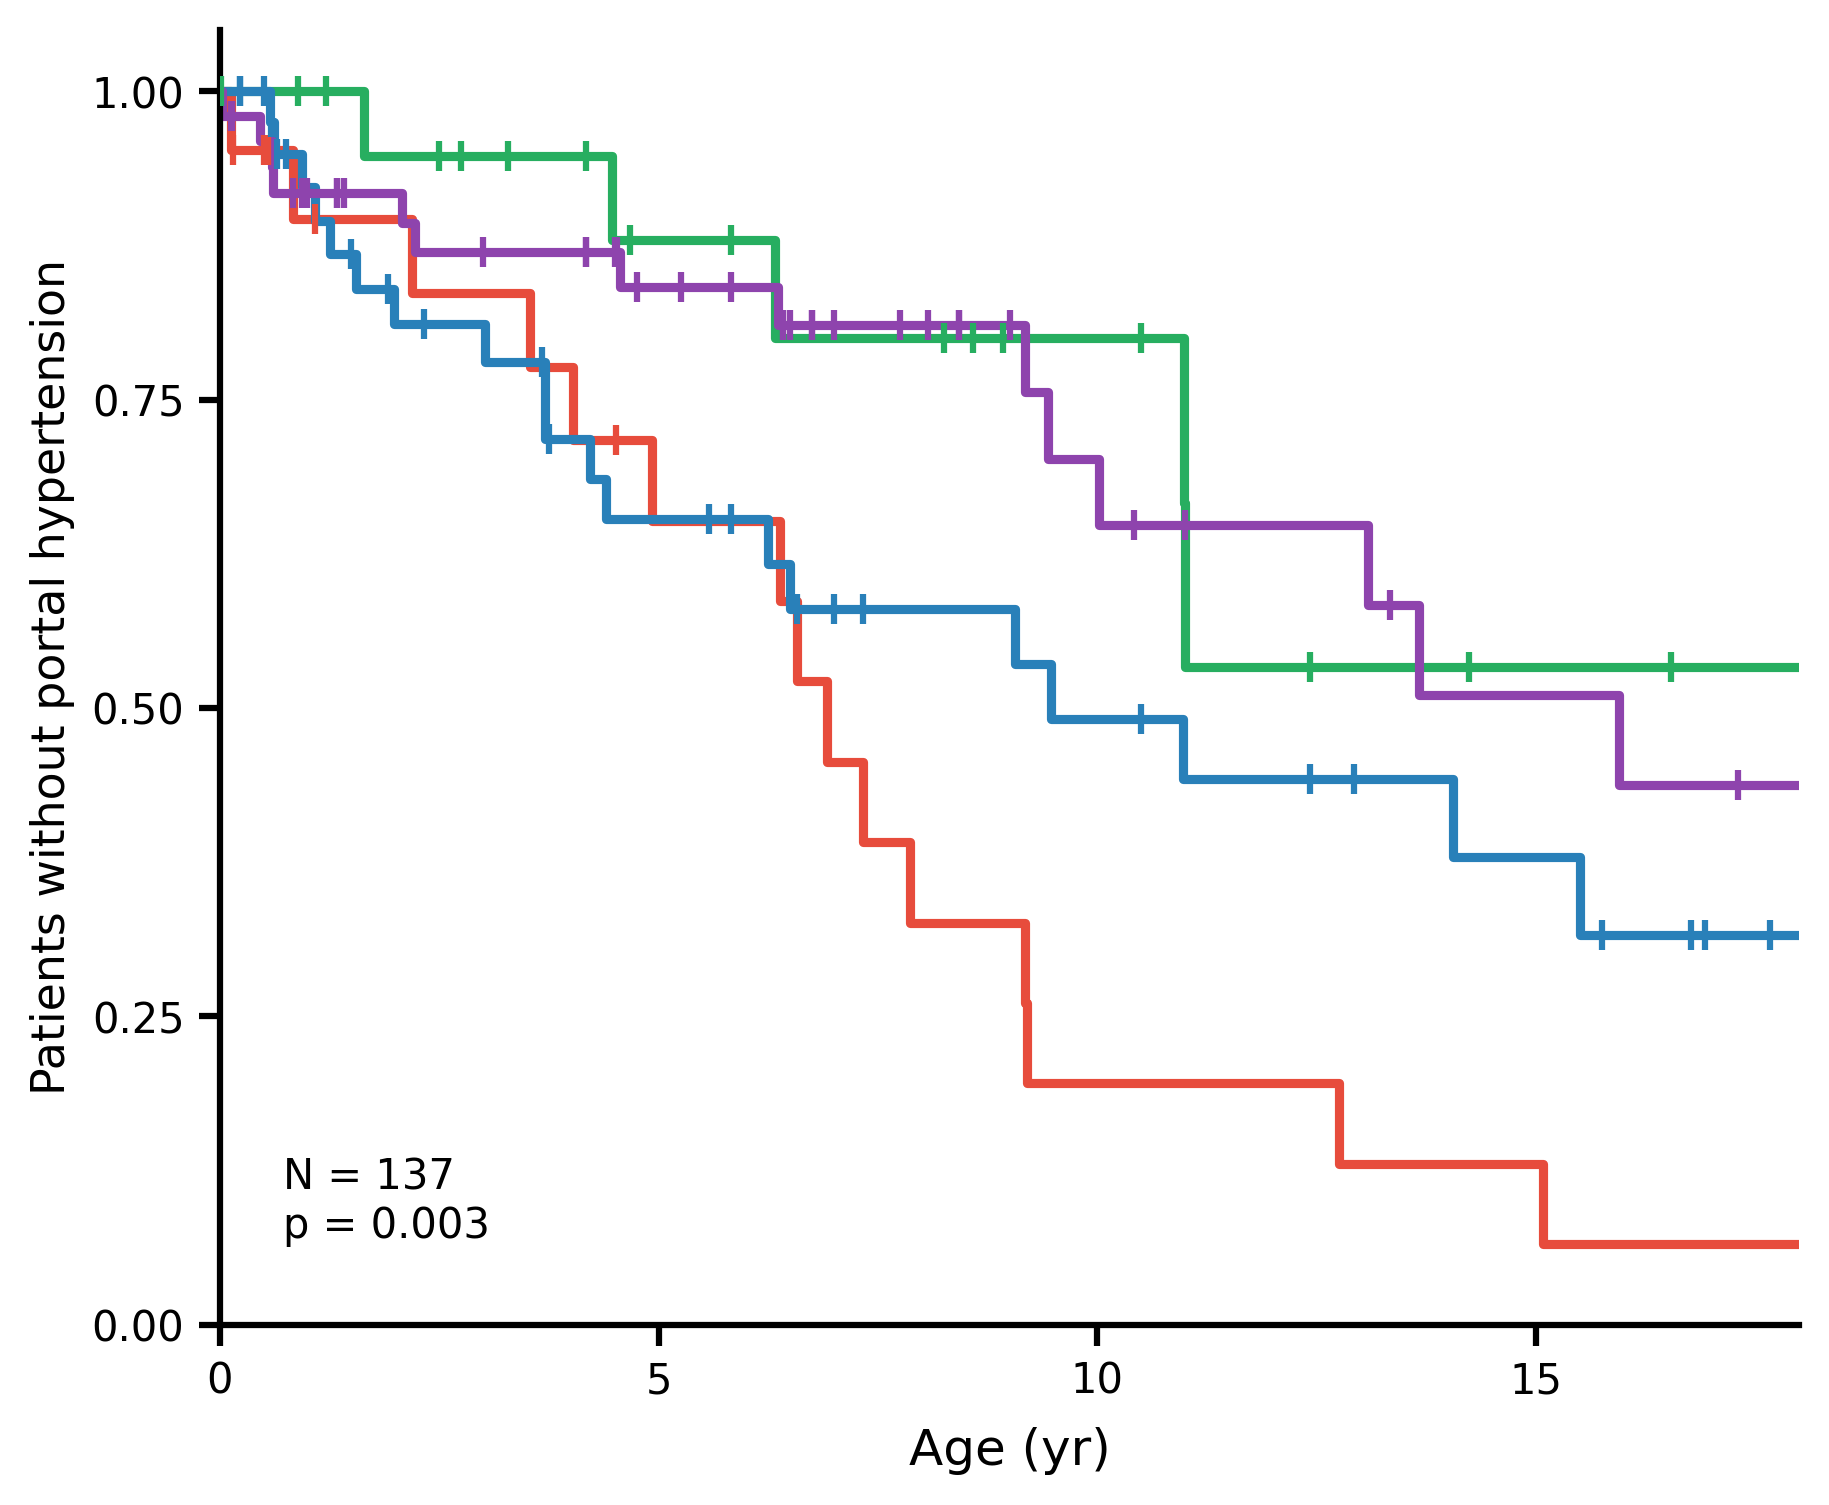


Burgmaier · Portal HTN · n=137, events=58
Overall four-group log-rank: chi²=13.8144, p = 0.003
Saved: /content/PKHD1_four_class_figures/km_portal_htn_burgmaier.png


,Group 1,Group 2,Log-rank p (raw),Holm-adjusted p
0,AA2625–4074,AA1838–2624,0.005811,0.029055
1,AA2625–4074,AA1–708,0.073248,0.292991
2,AA2625–4074,AA709–1837,0.000541,0.003247
3,AA1838–2624,AA1–708,0.104515,0.313545
4,AA1838–2624,AA709–1837,0.703687,0.703687
5,AA1–708,AA709–1837,0.237406,0.474812


Number at risk (actual KM-eligible patients):


,Group,N,Events,At risk 0y,At risk 5y,At risk 10y,At risk 15y
0,AA2625–4074,21,16,21,10,3,2
1,AA1838–2624,22,5,22,12,7,2
2,AA1–708,43,20,43,20,11,6
3,AA709–1837,51,17,51,29,13,7


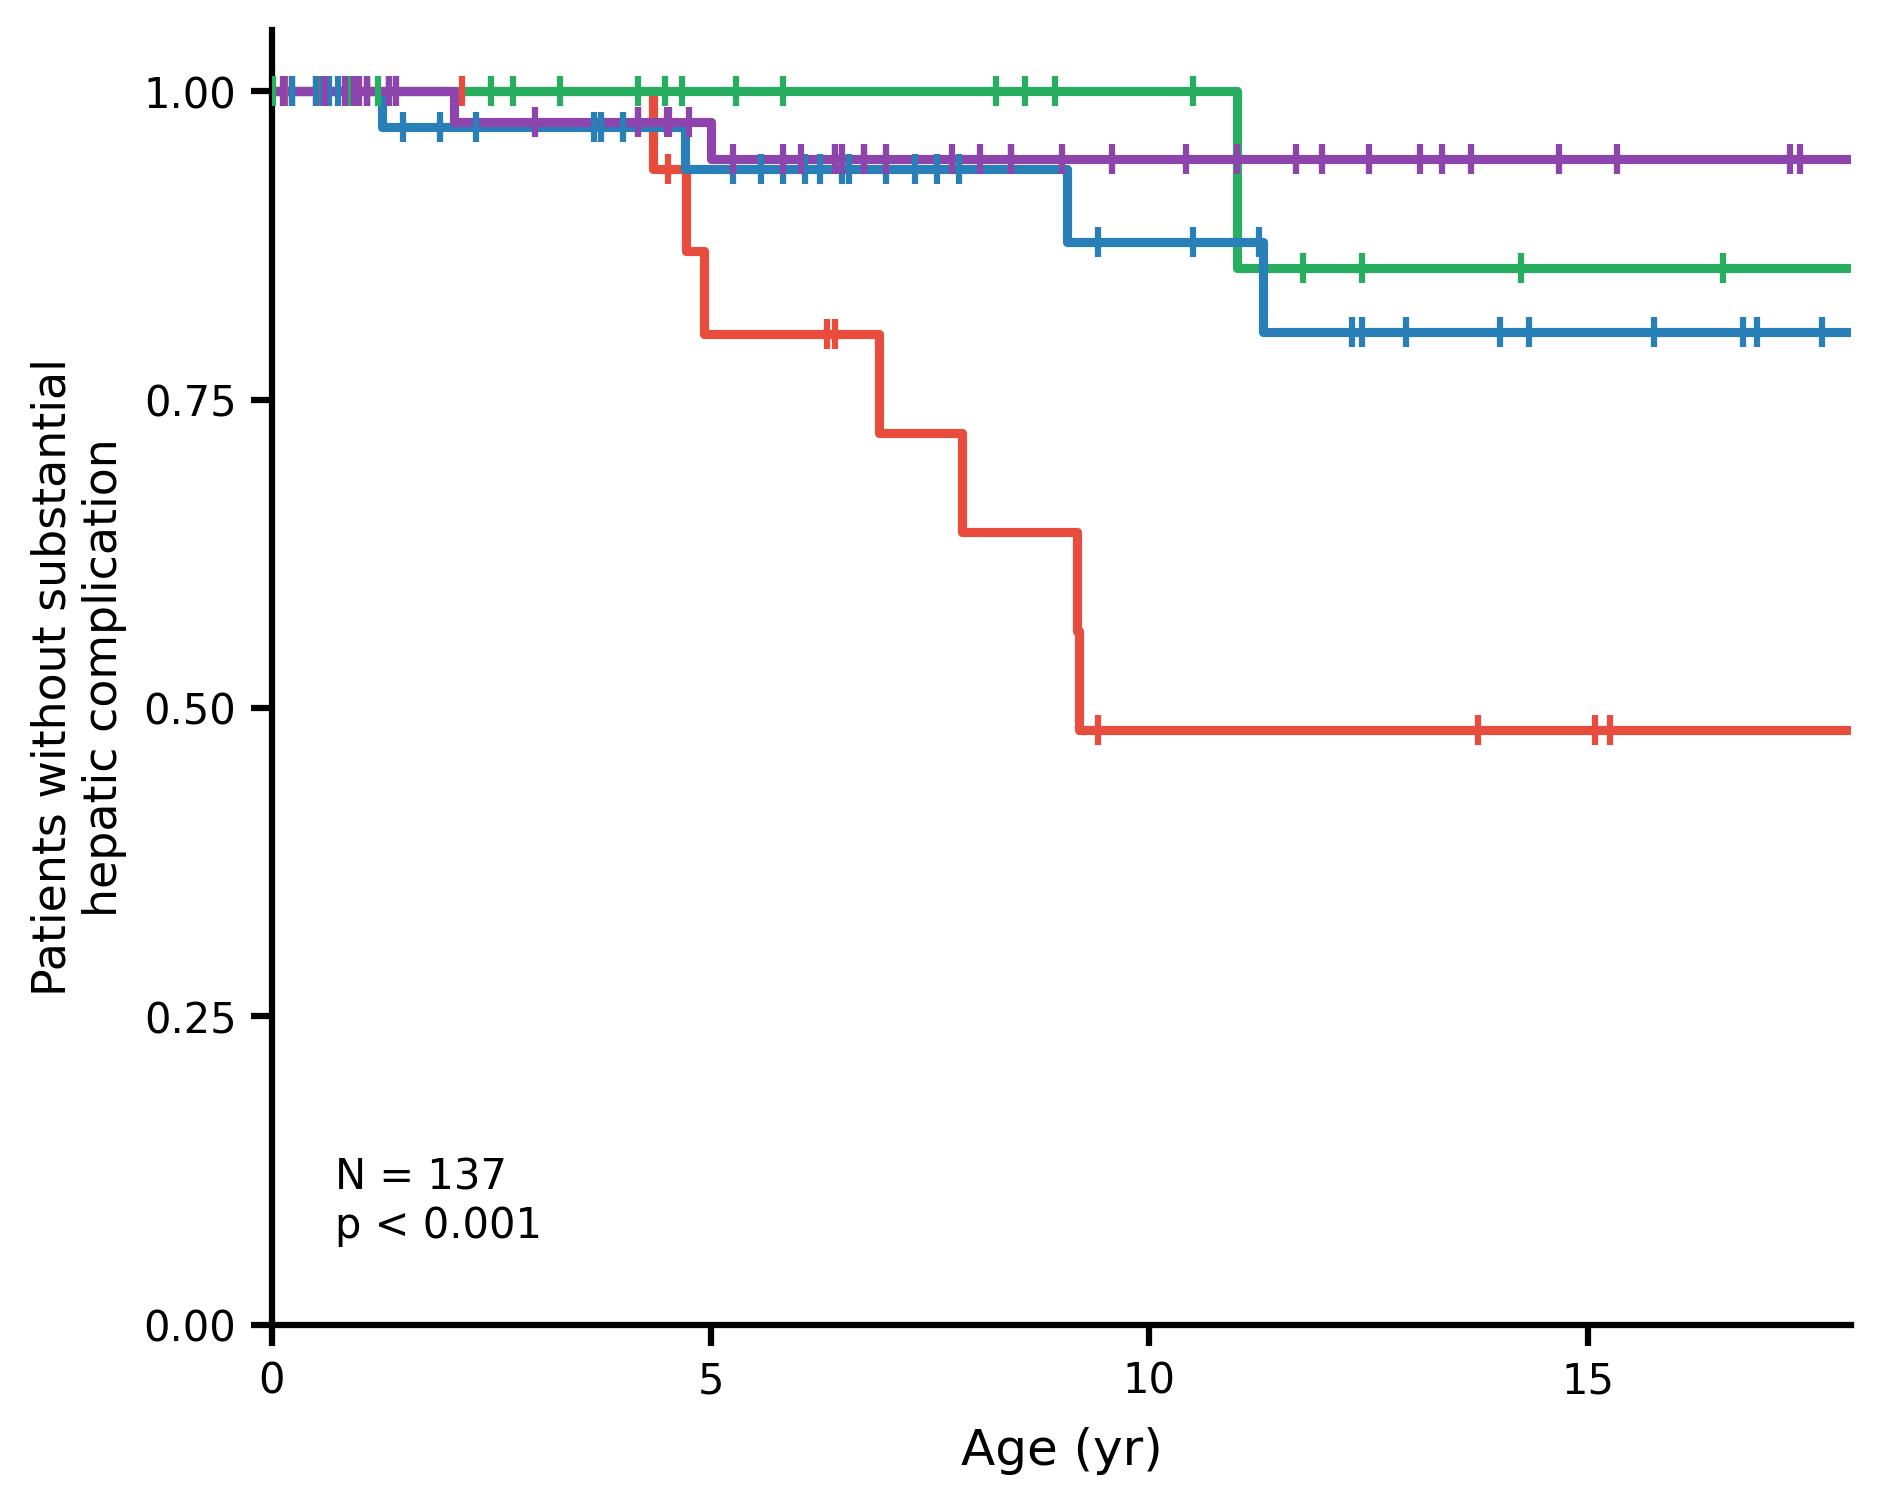


Burgmaier · Hepatic · n=137, events=17
Overall four-group log-rank: chi²=16.3537, p < 0.001
Saved: /content/PKHD1_four_class_figures/km_hepatic_burgmaier.png


,Group 1,Group 2,Log-rank p (raw),Holm-adjusted p
0,AA2625–4074,AA1838–2624,0.018935,0.094677
1,AA2625–4074,AA1–708,0.025151,0.100606
2,AA2625–4074,AA709–1837,0.000462,0.002772
3,AA1838–2624,AA1–708,0.516450,1.000000
4,AA1838–2624,AA709–1837,0.908914,1.000000
5,AA1–708,AA709–1837,0.548626,1.000000


Number at risk (actual KM-eligible patients):


,Group,N,Events,At risk 0y,At risk 5y,At risk 10y,At risk 15y
0,AA2625–4074,21,8,21,12,5,4
1,AA1838–2624,22,1,22,13,8,3
2,AA1–708,43,5,43,27,14,6
3,AA709–1837,51,3,51,33,17,8


Summary of overall four-class tests:


,endpoint,n,events,chi2,p
0,KRT,137,31,10.716108,0.013364
1,Portal HTN,137,58,13.814379,0.003169
2,Hepatic,137,17,16.353695,0.000960


In [5]:
plt.rcParams.update({
    'font.family':'DejaVu Sans',
    'font.size':11,
    'axes.linewidth':1.5,
    'axes.spines.top':False,
    'axes.spines.right':False,
    'xtick.major.width':1.5,
    'ytick.major.width':1.5,
    'xtick.major.size':5,
    'ytick.major.size':5,
    'figure.dpi':300,
    'figure.facecolor':'none',
    'axes.facecolor':'none',
})
TIMEPOINTS=[0,5,10,15]

def fmt_p(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'


def plot_four_classes(endpoint, ylabel, filename):
    data = SURVIVAL[endpoint]
    fig, ax = plt.subplots(figsize=(6.5,5.2))
    fig.patch.set_alpha(0)
    ax.patch.set_alpha(0)
    fig.subplots_adjust(left=0.16,right=0.97,top=0.96,bottom=0.13)

    for label in GROUP_ORDER:
        sub = data[data.group==label]
        if sub.empty: continue
        duration=sub.duration.to_numpy(dtype=float)
        event=sub.event.to_numpy(dtype=int)
        kmf=KaplanMeierFitter()
        kmf.fit(duration,event_observed=event,label=label)
        kmf.plot_survival_function(ax=ax,ci_show=False,
            color=COLORS[label],linewidth=2.2,label=label)
        t_cens = duration[event==0]
        if len(t_cens):
            p_cens=kmf.survival_function_at_times(t_cens).to_numpy()
            ax.scatter(t_cens,p_cens,marker='|',color=COLORS[label],
                       s=50,linewidth=1.5,zorder=5)

    overall=multivariate_logrank_test(data.duration,data.group,data.event)
    ax.text(0.04,0.06,f'N = {len(data)}\n{fmt_p(overall.p_value)}',
            transform=ax.transAxes,fontsize=10,va='bottom')
    if ax.get_legend():ax.get_legend().remove()
    ax.set_xlim(0,PLOT_END_YEAR)
    ax.set_ylim(0,1.05)
    ax.set_xlabel('Age (yr)',fontsize=12,labelpad=6)
    ax.set_ylabel(ylabel,fontsize=11)
    ax.set_xticks([0,5,10,15])
    ax.set_yticks([0,.25,.50,.75,1.00])
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x,_:f'{x:.2f}'))
    ax.tick_params(axis='both',labelsize=10)
    plot_path=OUTPUT_DIR/f'{filename}_{COHORT.lower()}.png'
    fig.savefig(plot_path,dpi=300,bbox_inches='tight',transparent=True)
    plt.show();plt.close(fig)

    # Single separate legend PNG in same style as existing notebook.
    legend_path=OUTPUT_DIR/'four_class_legend.png'
    if not legend_path.exists():
        fig_leg,ax_leg=plt.subplots(figsize=(4.0,1.6))
        fig_leg.patch.set_alpha(0);ax_leg.patch.set_alpha(0)
        ax_leg.axis('off')
        handles=[plt.Line2D([0],[0],color=COLORS[g],linewidth=2.5) for g in GROUP_ORDER]
        ax_leg.legend(handles,GROUP_ORDER,loc='center left',fontsize=9,
                      frameon=False,handlelength=2.0,labelspacing=0.7)
        fig_leg.savefig(legend_path,dpi=300,bbox_inches='tight',transparent=True)
        plt.close(fig_leg)

    print(f'\n{COHORT} · {endpoint} · n={len(data)}, events={int(data.event.sum())}')
    print(f'Overall four-group log-rank: chi²={overall.test_statistic:.4f}, {fmt_p(overall.p_value)}')
    print('Saved:',plot_path)

    # Six pairwise comparisons, with Holm adjustment to guard against multiplicity.
    pairs=[]
    for g1,g2 in itertools.combinations(GROUP_ORDER,2):
        a,b=data[data.group==g1],data[data.group==g2]
        test=logrank_test(a.duration,b.duration,a.event,b.event)
        pairs.append((g1,g2,float(test.p_value)))
    ps=np.array([x[2] for x in pairs]); order=np.argsort(ps)
    adj=np.empty(len(ps)); k=len(ps)
    prev=0
    for rank,i in enumerate(order):
        prev=max(prev,min(1.,(k-rank)*ps[i])); adj[i]=prev
    pair_df=pd.DataFrame({'Group 1':[x[0] for x in pairs],
        'Group 2':[x[1] for x in pairs], 'Log-rank p (raw)':ps,
        'Holm-adjusted p':adj})
    display(pair_df)

    risk=[]
    for label in GROUP_ORDER:
        s=data[data.group==label]
        record={'Group':label,'N':len(s),'Events':int(s.event.sum())}
        for t in TIMEPOINTS:record[f'At risk {t}y']=int((s.duration>=t).sum())
        risk.append(record)
    risk_df=pd.DataFrame(risk)
    print('Number at risk (actual KM-eligible patients):')
    display(risk_df)
    return {'endpoint':endpoint,'n':len(data),'events':int(data.event.sum()),
            'chi2':float(overall.test_statistic),'p':float(overall.p_value)}, pair_df, risk_df

stats=[]; pair_tables=[]; risk_tables=[]
for endpoint,ylabel,fname in ENDPOINTS:
    result,pairs,risk=plot_four_classes(endpoint,ylabel,fname)
    stats.append(result)
    pairs.insert(0,'Endpoint',endpoint);pair_tables.append(pairs)
    risk.insert(0,'Endpoint',endpoint);risk_tables.append(risk)

stats_df=pd.DataFrame(stats)
print('Summary of overall four-class tests:')
display(stats_df)

In [6]:
import shutil
stats_df.to_csv(OUTPUT_DIR/f'overall_4_class_{COHORT.lower()}.csv',index=False)
pd.concat(pair_tables,ignore_index=True).to_csv(
    OUTPUT_DIR/f'pairwise_4_class_{COHORT.lower()}.csv',index=False)
pd.concat(risk_tables,ignore_index=True).to_csv(
    OUTPUT_DIR/f'at_risk_4_class_{COHORT.lower()}.csv',index=False)
archive=shutil.make_archive(f'/content/PKHD1_4_class_{COHORT.lower()}', 'zip', OUTPUT_DIR)
print('Saved archive:',archive)
# Uncomment in Colab if you want immediate download:
# files.download(archive)

Saved archive: /content/PKHD1_4_class_burgmaier.zip


# NephVar

In [7]:
from google.colab import files

COHORT = 'NephVar'
PLOT_END_YEAR = 18       # identical to AA709_1837.ipynb
OUTPUT_DIR = Path('/content/PKHD1_NephVar_four_class_figures')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

NEPHVAR_CSV = Path('/content/NephVar Database - PKHD1 (5).csv')
# To run the most recently uploaded NephVar version instead, use:
# NEPHVAR_CSV = Path('/content/NephVar Database - PKHD1 (6).csv')

CSV_PATHS = {'NephVar': NEPHVAR_CSV}
if not NEPHVAR_CSV.is_file():
    print(f'Please upload: {NEPHVAR_CSV.name}')
    files.upload()
assert NEPHVAR_CSV.is_file(), f'Missing input CSV at {NEPHVAR_CSV}'
print('Running NephVar only:', NEPHVAR_CSV)
print('Figure output:', OUTPUT_DIR)


Running NephVar only: /content/NephVar Database - PKHD1 (5).csv
Figure output: /content/PKHD1_NephVar_four_class_figures


In [8]:
REGIONS = [
    ('AA2625–4074', 'Mis2625-4074', '#e74c3c'),
    ('AA1838–2624', 'Mis1838-2624', '#27ae60'),
    ('AA1–708',      'Mis1-708',      '#2980b9'),
    ('AA709–1837',   'Mis709-1837',   '#8e44ad'),
]
GROUP_ORDER = [x[0] for x in REGIONS]
COLORS = dict((label,color) for label,_,color in REGIONS)


def extract_age(value):
    """Only read a number at the start; '-' and unreported ages => NaN."""
    m = re.match(r'^\s*([+-]?(?:\d+(?:\.\d*)?|\.\d+))', str(value))
    return float(m.group(1)) if m else np.nan


def column_starting(df, prefix):
    xs = [c for c in df if c.lower().startswith(prefix.lower())]
    if len(xs) != 1:
        raise ValueError(f'Expected one column starting {prefix!r}, got {xs}')
    return xs[0]


def load_cohort(name):
    df = pd.read_csv(CSV_PATHS[name], dtype=str)
    # Exclude non-patient notes, empty rows, and trailing spreadsheet summaries.
    df = df.loc[df['Predicted protein change'].notna()].copy()
    df['source_row'] = df.index + 2  # original spreadsheet row (1-based, incl. header)
    norm = df['Functional class'].fillna('').str.replace(r'\s+', '', regex=True)
    df['group'] = pd.Series(pd.NA,index=df.index,dtype='object')
    for label,region,_ in REGIONS:
        allowed = {f'Null/{region}',f'{region}/Null',f'{region}/{region}'}
        df.loc[norm.isin(allowed),'group'] = label

    df['fu_raw'] = df[column_starting(df,'Last follow-')]
    df['fu'] = df['fu_raw'].map(extract_age)
    df['termination'] = df['fu_raw'].fillna('').str.contains('termination|terminated',case=False,regex=True)
    raw_events = {
        'KRT': column_starting(df,'KRT ('),
        'Portal HTN': column_starting(df,'Portal HTN'),
        'Hepatic': next(c for c in df if 'hepatic compli' in c.lower()),
    }
    for key, col in raw_events.items():
        df[f'{key}_age'] = df[col].map(extract_age)
    df['cohort'] = name
    return df

D = load_cohort(COHORT)
FOUR = D[D['group'].notna()].copy()
print(f'{COHORT}: {len(D)} patient records; {len(FOUR)} in the four groups')
print('Excluded other/mixed classes:', len(D)-len(FOUR))
display(FOUR.groupby('group').size().reindex(GROUP_ORDER).rename('Patients (before survival filtering)').to_frame())

if COHORT == 'Burgmaier':
    expected = {'AA2625–4074':21,'AA1838–2624':22,'AA1–708':44,'AA709–1837':51}
    observed = FOUR['group'].value_counts().to_dict()
    assert observed == expected, f'Burgmaier group count mismatch: {observed}'

NephVar: 329 patient records; 172 in the four groups
Excluded other/mixed classes: 157


,Patients (before survival filtering)
group,
AA2625–4074,41
AA1838–2624,21
AA1–708,48
AA709–1837,62


In [9]:
ENDPOINTS = [
    ('KRT', 'Patients without KRT','km_krt'),
    ('Portal HTN','Patients without portal hypertension','km_portal_htn'),
    ('Hepatic','Patients without documented\nhepatic involvement','km_hepatic'),
]

def survival_data(raw, endpoint):
    df = raw.copy()
    event_age = df[f'{endpoint}_age'].astype(float)
    df['event'] = event_age.notna().astype(int)
    df['duration'] = np.where(df['event'] == 1, event_age, df['fu'])
    df.loc[(df['event'] == 0) & (df['duration'] <= 0),'duration'] = np.nan
    df.loc[(df['event'] == 1) & (df['duration'] <= 0),'duration'] = 0.001
    df.loc[df['termination'],'duration'] = np.nan
    return df.loc[df['group'].notna() & df['duration'].notna()].copy()

SURVIVAL = {name:survival_data(FOUR,name) for name,_,_ in ENDPOINTS}
for endpoint,_,_ in ENDPOINTS:
    v = SURVIVAL[endpoint]
    print(f'{endpoint}: KM n={len(v)}; events={int(v.event.sum())}; censored={int((1-v.event).sum())}')
    conflict = v[(v.event==1)&(v.fu.notna())&(v[f'{endpoint}_age'] > v.fu+1e-9)]
    if len(conflict):
        print('  REVIEW: event age after last follow-up (not auto-corrected):')
        display(conflict[['source_row','group',f'{endpoint}_age','fu','Predicted protein change']])

KRT: KM n=136; events=23; censored=113
Portal HTN: KM n=135; events=23; censored=112
Hepatic: KM n=143; events=45; censored=98


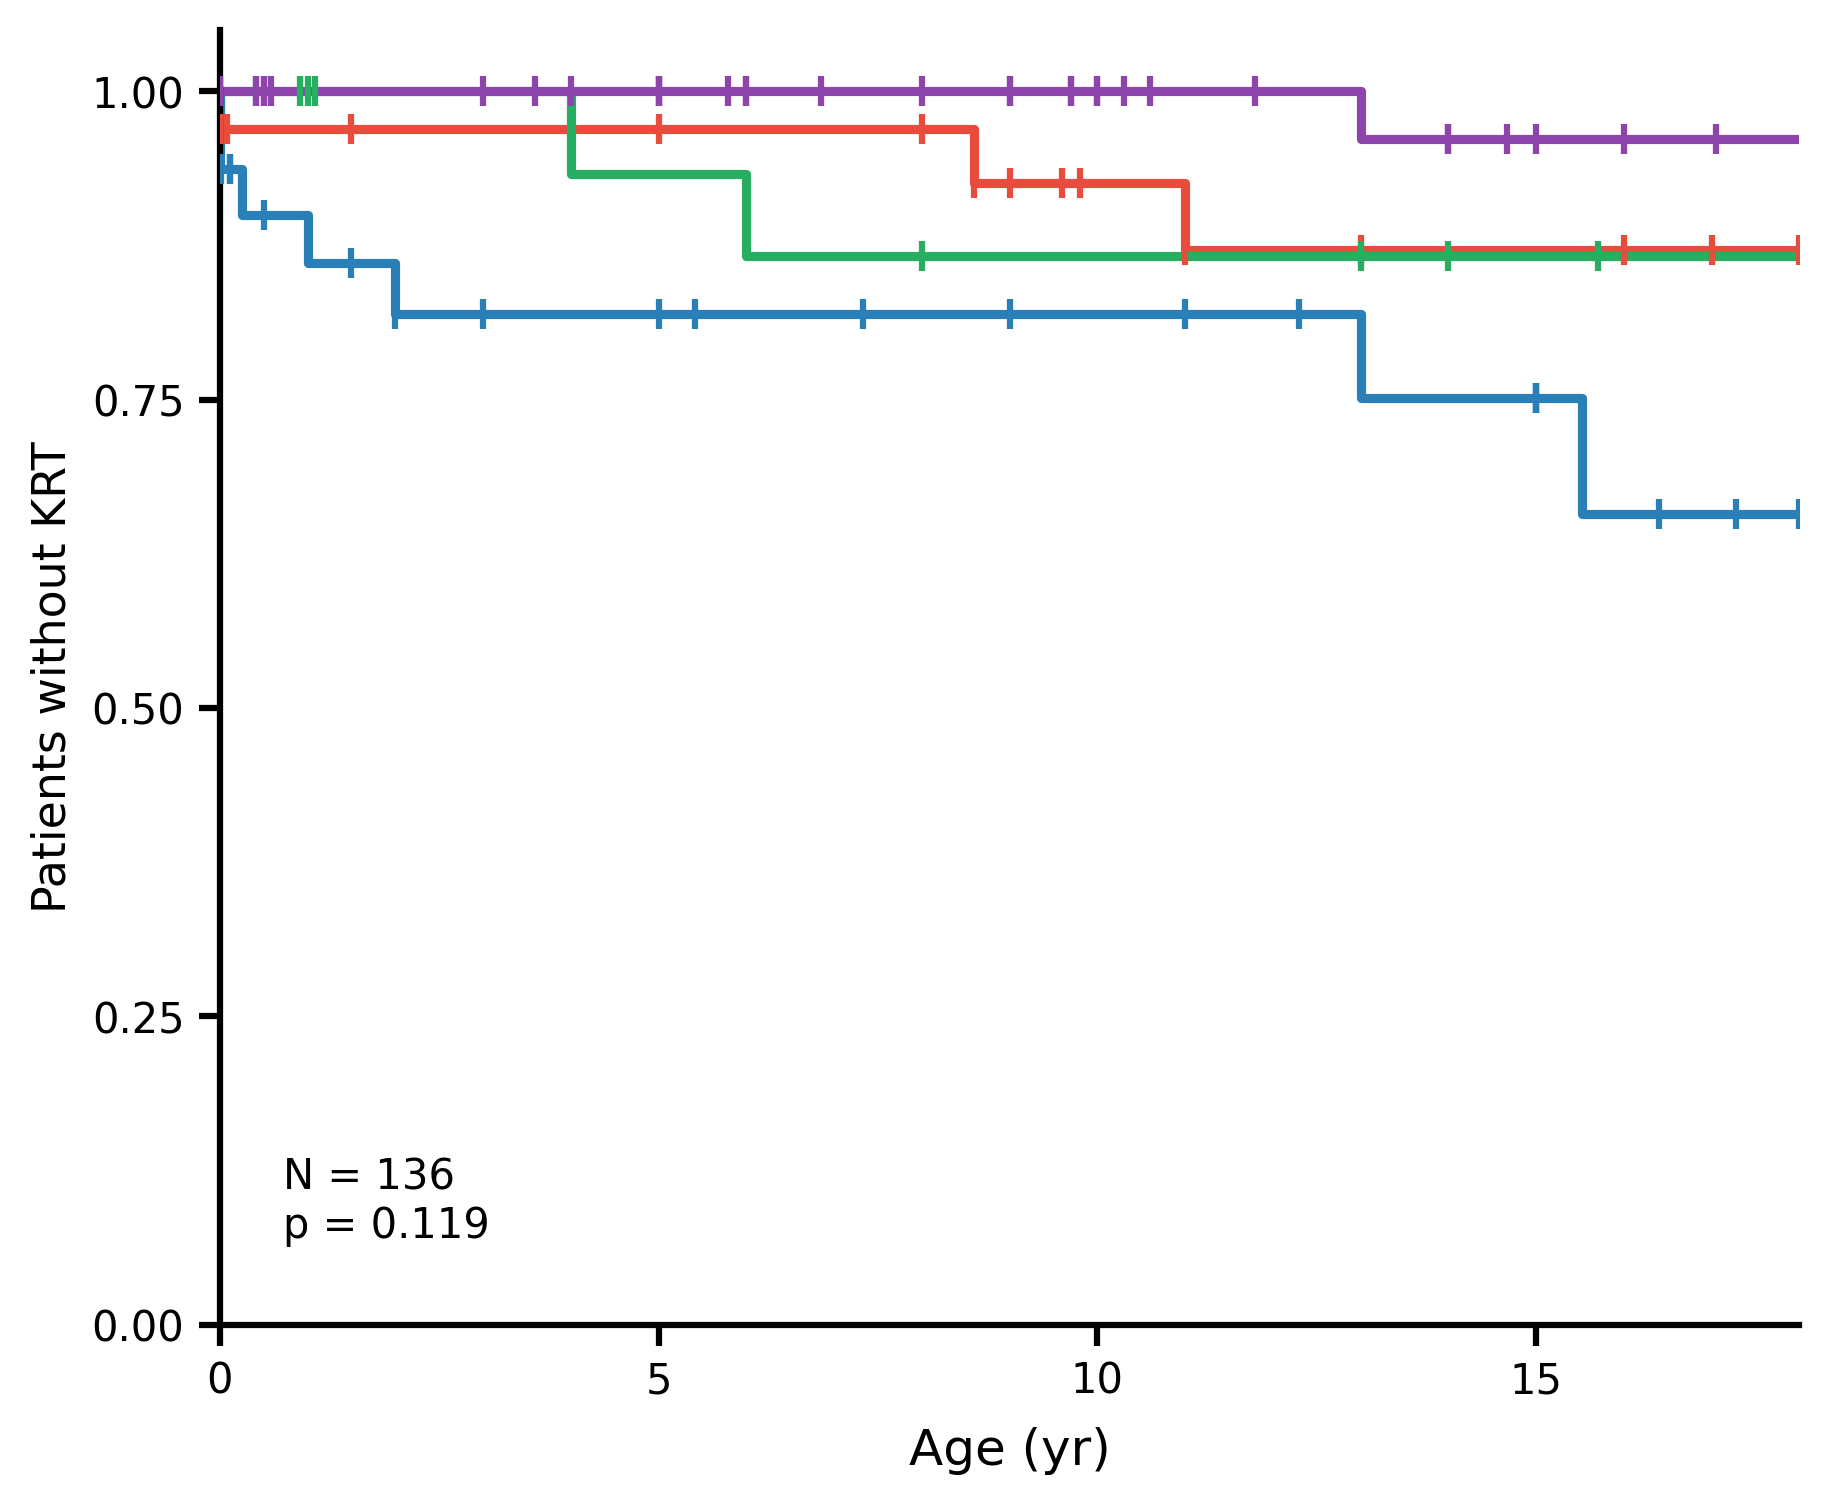


NephVar · KRT · n=136, events=23
Overall four-group log-rank: chi²=5.8534, p = 0.119
Saved: /content/PKHD1_NephVar_four_class_figures/km_krt_nephvar.png


,Group 1,Group 2,Log-rank p (raw),Holm-adjusted p
0,AA2625–4074,AA1838–2624,0.663315,1.000000
1,AA2625–4074,AA1–708,0.193989,0.969943
2,AA2625–4074,AA709–1837,0.331884,1.000000
3,AA1838–2624,AA1–708,0.379578,1.000000
4,AA1838–2624,AA709–1837,0.630496,1.000000
5,AA1–708,AA709–1837,0.020591,0.123544


Number at risk (actual KM-eligible patients):


,Group,N,Events,At risk 0y,At risk 5y,At risk 10y,At risk 15y
0,AA2625–4074,33,5,33,24,17,14
1,AA1838–2624,19,5,19,14,12,10
2,AA1–708,32,7,32,18,14,11
3,AA709–1837,52,6,52,43,31,22


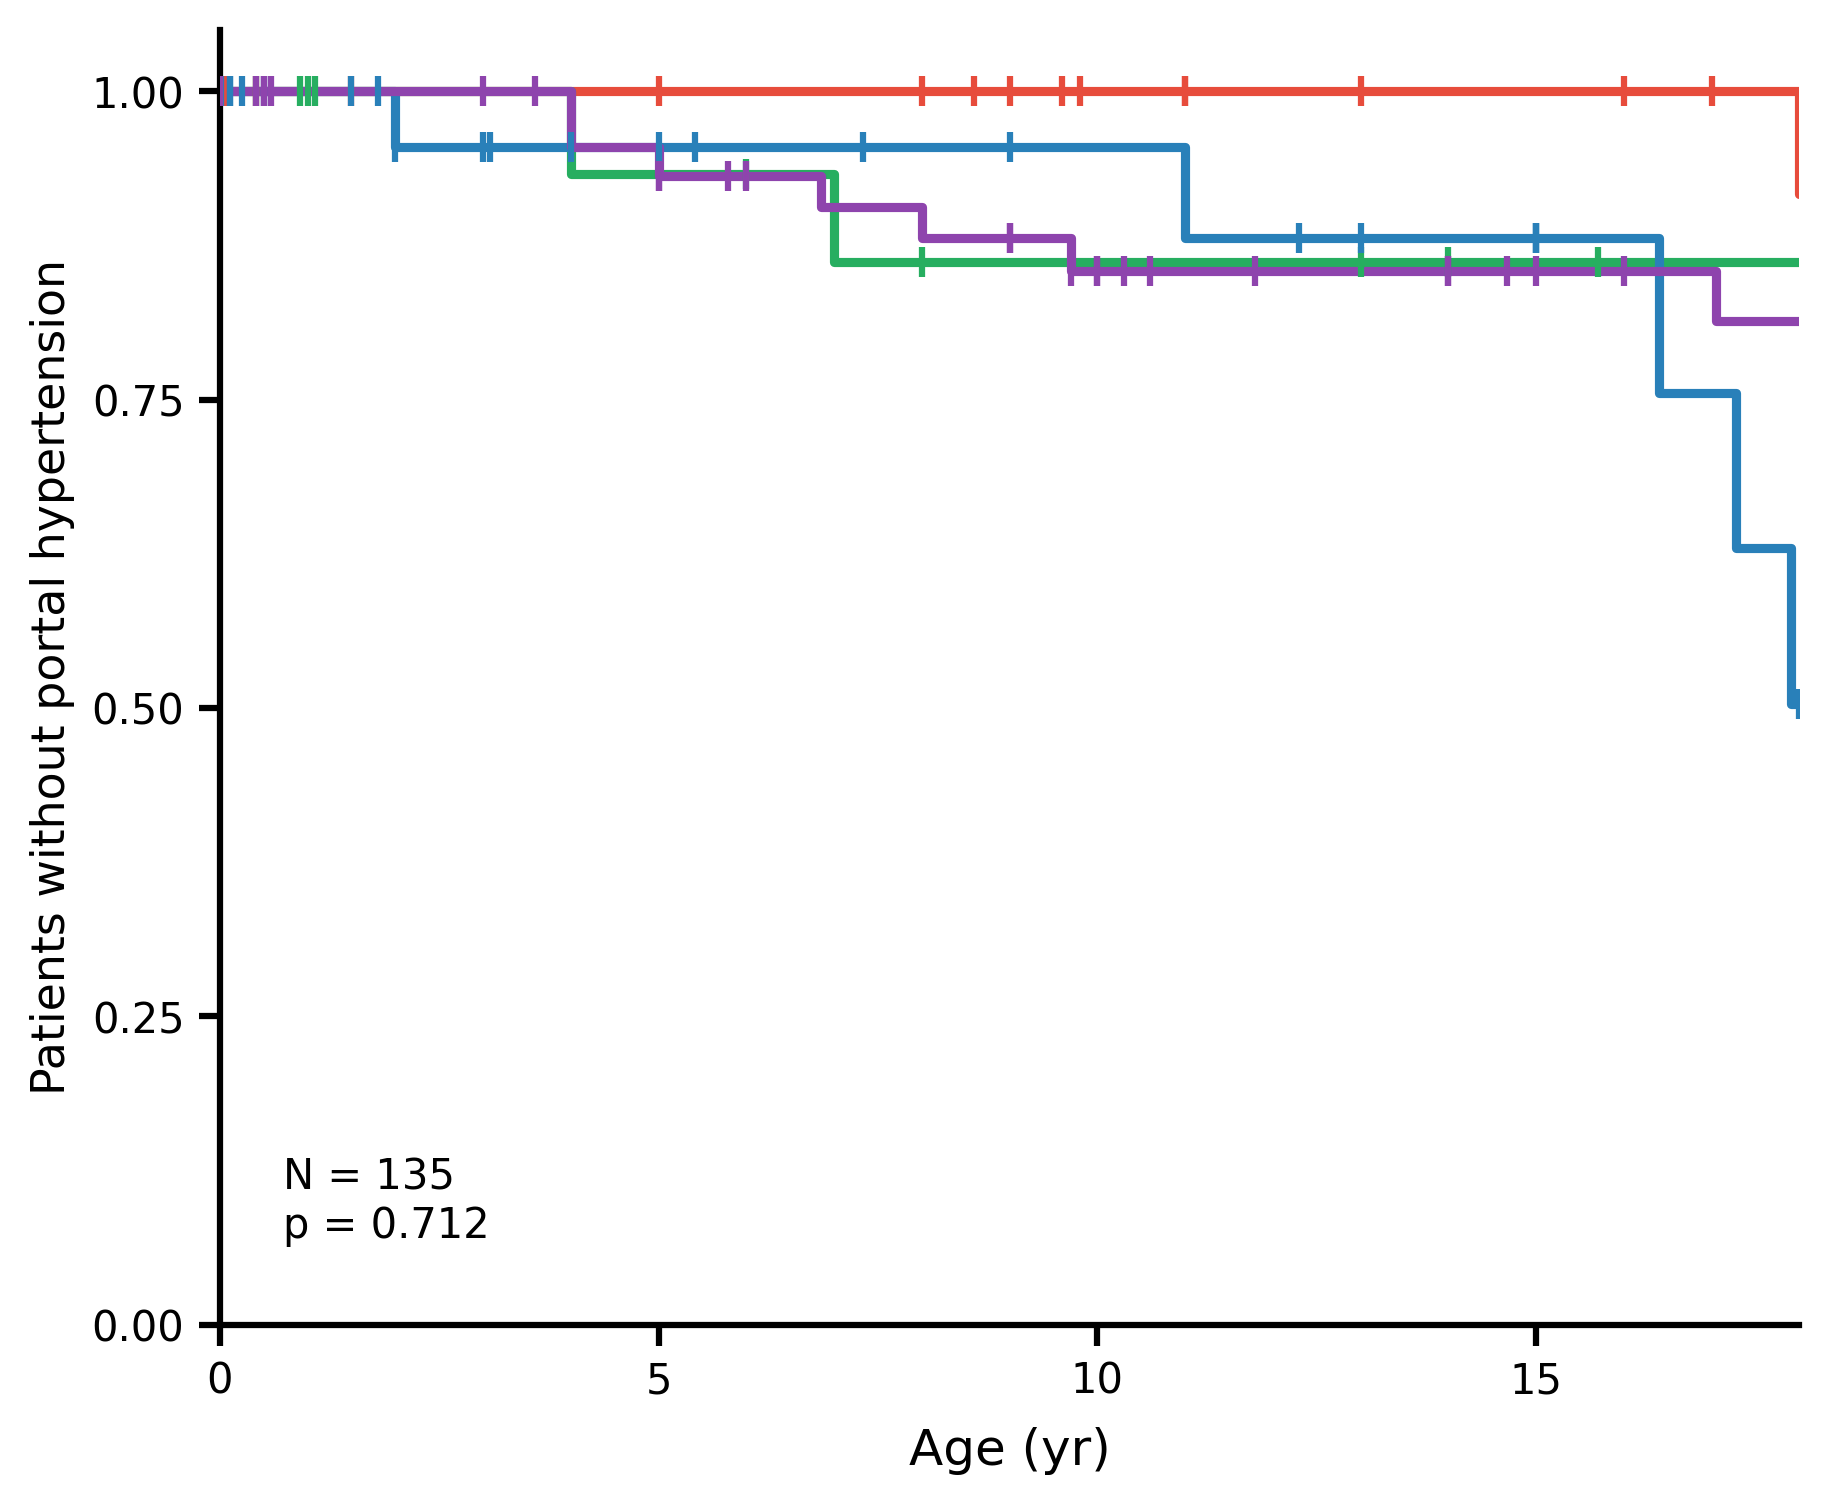


NephVar · Portal HTN · n=135, events=23
Overall four-group log-rank: chi²=1.3704, p = 0.712
Saved: /content/PKHD1_NephVar_four_class_figures/km_portal_htn_nephvar.png


,Group 1,Group 2,Log-rank p (raw),Holm-adjusted p
0,AA2625–4074,AA1838–2624,0.705249,1.0
1,AA2625–4074,AA1–708,0.167774,1.0
2,AA2625–4074,AA709–1837,0.937576,1.0
3,AA1838–2624,AA1–708,0.538335,1.0
4,AA1838–2624,AA709–1837,0.821431,1.0
5,AA1–708,AA709–1837,0.291464,1.0


Number at risk (actual KM-eligible patients):


,Group,N,Events,At risk 0y,At risk 5y,At risk 10y,At risk 15y
0,AA2625–4074,32,5,32,23,17,14
1,AA1838–2624,19,5,19,14,11,9
2,AA1–708,32,5,32,17,13,10
3,AA709–1837,52,8,52,42,31,23


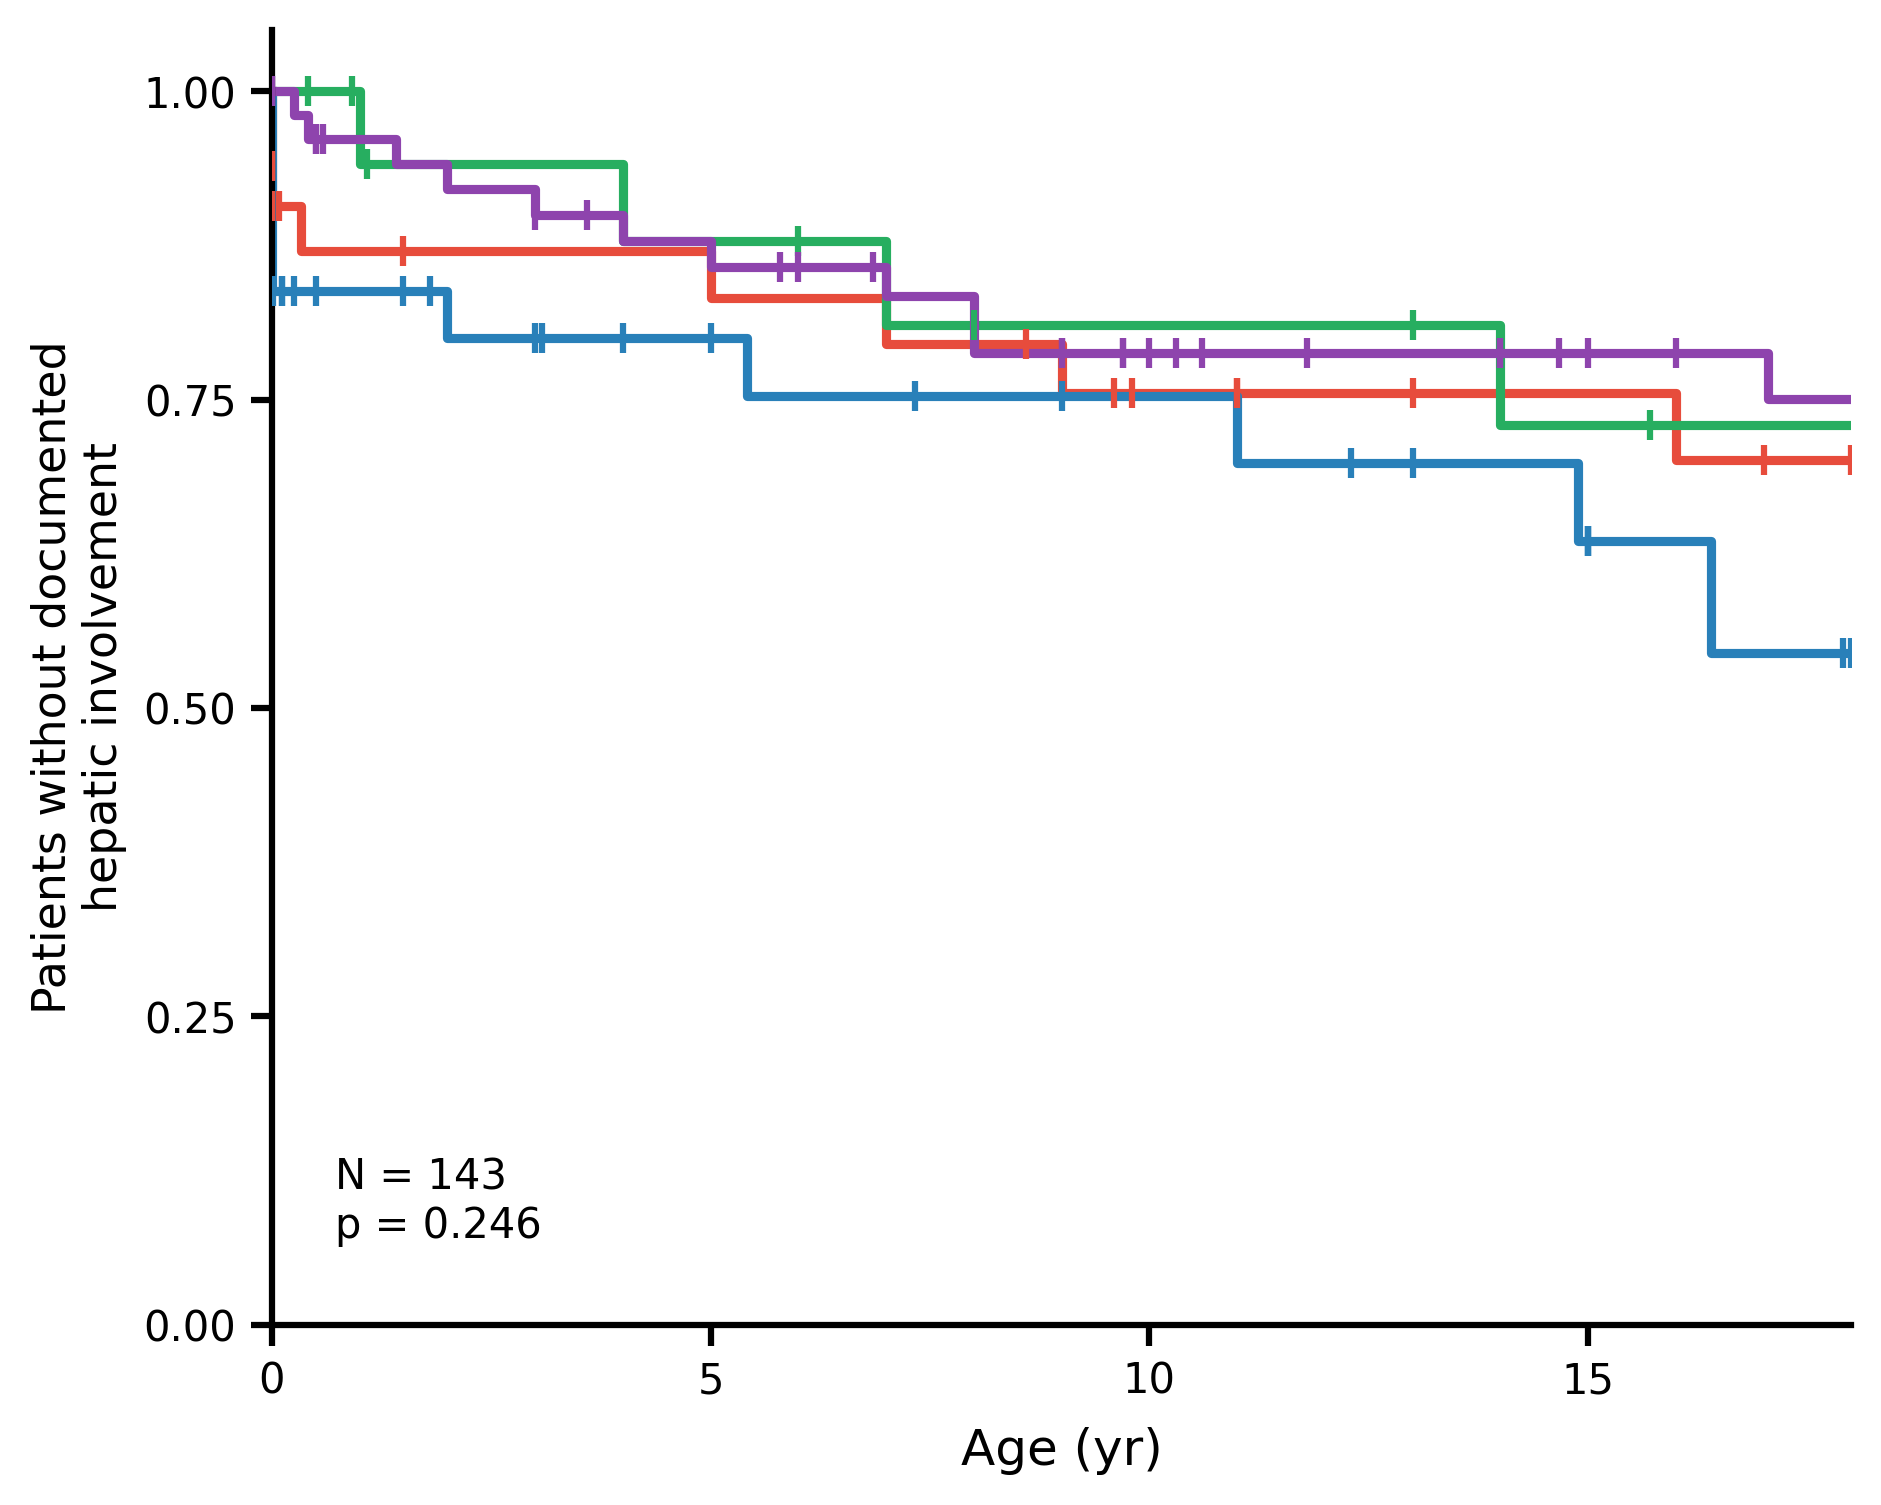


NephVar · Hepatic · n=143, events=45
Overall four-group log-rank: chi²=4.1452, p = 0.246
Saved: /content/PKHD1_NephVar_four_class_figures/km_hepatic_nephvar.png


,Group 1,Group 2,Log-rank p (raw),Holm-adjusted p
0,AA2625–4074,AA1838–2624,0.484334,1.000000
1,AA2625–4074,AA1–708,0.363808,1.000000
2,AA2625–4074,AA709–1837,0.221987,1.000000
3,AA1838–2624,AA1–708,0.320623,1.000000
4,AA1838–2624,AA709–1837,0.630036,1.000000
5,AA1–708,AA709–1837,0.053866,0.323199


Number at risk (actual KM-eligible patients):


,Group,N,Events,At risk 0y,At risk 5y,At risk 10y,At risk 15y
0,AA2625–4074,33,12,33,23,17,14
1,AA1838–2624,19,8,19,14,11,9
2,AA1–708,37,12,37,18,14,10
3,AA709–1837,54,13,54,41,30,23


Summary of overall four-class tests:


,endpoint,n,events,chi2,p
0,KRT,136,23,5.853370,0.118966
1,Portal HTN,135,23,1.370447,0.712476
2,Hepatic,143,45,4.145229,0.246203


In [10]:
plt.rcParams.update({
    'font.family':'DejaVu Sans',
    'font.size':11,
    'axes.linewidth':1.5,
    'axes.spines.top':False,
    'axes.spines.right':False,
    'xtick.major.width':1.5,
    'ytick.major.width':1.5,
    'xtick.major.size':5,
    'ytick.major.size':5,
    'figure.dpi':300,
    'figure.facecolor':'none',
    'axes.facecolor':'none',
})
TIMEPOINTS=[0,5,10,15]

def fmt_p(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'


def plot_four_classes(endpoint, ylabel, filename):
    data = SURVIVAL[endpoint]
    fig, ax = plt.subplots(figsize=(6.5,5.2))
    fig.patch.set_alpha(0)
    ax.patch.set_alpha(0)
    fig.subplots_adjust(left=0.16,right=0.97,top=0.96,bottom=0.13)

    for label in GROUP_ORDER:
        sub = data[data.group==label]
        if sub.empty: continue
        duration=sub.duration.to_numpy(dtype=float)
        event=sub.event.to_numpy(dtype=int)
        kmf=KaplanMeierFitter()
        kmf.fit(duration,event_observed=event,label=label)
        kmf.plot_survival_function(ax=ax,ci_show=False,
            color=COLORS[label],linewidth=2.2,label=label)
        t_cens = duration[event==0]
        if len(t_cens):
            p_cens=kmf.survival_function_at_times(t_cens).to_numpy()
            ax.scatter(t_cens,p_cens,marker='|',color=COLORS[label],
                       s=50,linewidth=1.5,zorder=5)

    overall=multivariate_logrank_test(data.duration,data.group,data.event)
    ax.text(0.04,0.06,f'N = {len(data)}\n{fmt_p(overall.p_value)}',
            transform=ax.transAxes,fontsize=10,va='bottom')
    if ax.get_legend():ax.get_legend().remove()
    ax.set_xlim(0,PLOT_END_YEAR)
    ax.set_ylim(0,1.05)
    ax.set_xlabel('Age (yr)',fontsize=12,labelpad=6)
    ax.set_ylabel(ylabel,fontsize=11)
    ax.set_xticks([0,5,10,15])
    ax.set_yticks([0,.25,.50,.75,1.00])
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x,_:f'{x:.2f}'))
    ax.tick_params(axis='both',labelsize=10)
    plot_path=OUTPUT_DIR/f'{filename}_{COHORT.lower()}.png'
    fig.savefig(plot_path,dpi=300,bbox_inches='tight',transparent=True)
    plt.show();plt.close(fig)

    # Single separate legend PNG in same style as existing notebook.
    legend_path=OUTPUT_DIR/'four_class_legend.png'
    if not legend_path.exists():
        fig_leg,ax_leg=plt.subplots(figsize=(4.0,1.6))
        fig_leg.patch.set_alpha(0);ax_leg.patch.set_alpha(0)
        ax_leg.axis('off')
        handles=[plt.Line2D([0],[0],color=COLORS[g],linewidth=2.5) for g in GROUP_ORDER]
        ax_leg.legend(handles,GROUP_ORDER,loc='center left',fontsize=9,
                      frameon=False,handlelength=2.0,labelspacing=0.7)
        fig_leg.savefig(legend_path,dpi=300,bbox_inches='tight',transparent=True)
        plt.close(fig_leg)

    print(f'\n{COHORT} · {endpoint} · n={len(data)}, events={int(data.event.sum())}')
    print(f'Overall four-group log-rank: chi²={overall.test_statistic:.4f}, {fmt_p(overall.p_value)}')
    print('Saved:',plot_path)

    # Six pairwise comparisons, with Holm adjustment to guard against multiplicity.
    pairs=[]
    for g1,g2 in itertools.combinations(GROUP_ORDER,2):
        a,b=data[data.group==g1],data[data.group==g2]
        test=logrank_test(a.duration,b.duration,a.event,b.event)
        pairs.append((g1,g2,float(test.p_value)))
    ps=np.array([x[2] for x in pairs]); order=np.argsort(ps)
    adj=np.empty(len(ps)); k=len(ps)
    prev=0
    for rank,i in enumerate(order):
        prev=max(prev,min(1.,(k-rank)*ps[i])); adj[i]=prev
    pair_df=pd.DataFrame({'Group 1':[x[0] for x in pairs],
        'Group 2':[x[1] for x in pairs], 'Log-rank p (raw)':ps,
        'Holm-adjusted p':adj})
    display(pair_df)

    risk=[]
    for label in GROUP_ORDER:
        s=data[data.group==label]
        record={'Group':label,'N':len(s),'Events':int(s.event.sum())}
        for t in TIMEPOINTS:record[f'At risk {t}y']=int((s.duration>=t).sum())
        risk.append(record)
    risk_df=pd.DataFrame(risk)
    print('Number at risk (actual KM-eligible patients):')
    display(risk_df)
    return {'endpoint':endpoint,'n':len(data),'events':int(data.event.sum()),
            'chi2':float(overall.test_statistic),'p':float(overall.p_value)}, pair_df, risk_df

stats=[]; pair_tables=[]; risk_tables=[]
for endpoint,ylabel,fname in ENDPOINTS:
    result,pairs,risk=plot_four_classes(endpoint,ylabel,fname)
    stats.append(result)
    pairs.insert(0,'Endpoint',endpoint);pair_tables.append(pairs)
    risk.insert(0,'Endpoint',endpoint);risk_tables.append(risk)

stats_df=pd.DataFrame(stats)
print('Summary of overall four-class tests:')
display(stats_df)

# Pooled

In [11]:
from google.colab import files

COHORT = 'Pooled'
PLOT_END_YEAR = 18             # identical to AA709_1837.ipynb
OUTPUT_DIR = Path('/content/PKHD1_pooled_four_class_figures')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATHS = {
    'Burgmaier': Path('/content/Burgmaier_Genotype_Phenotype_Replication - Burgmaier_S3_Source (2).csv'),
    'NephVar': Path('/content/NephVar Database - PKHD1 (5).csv'),
}

missing = [p for p in CSV_PATHS.values() if not p.is_file()]
if missing:
    print('Upload both missing files to /content:')
    for p in missing: print('  ', p.name)
    files.upload()
for name, path in CSV_PATHS.items():
    assert path.is_file(), f'Missing {name} CSV: {path}'
    print(f'{name}: {path.name}')
print('Output folder:', OUTPUT_DIR)


Burgmaier: Burgmaier_Genotype_Phenotype_Replication - Burgmaier_S3_Source (2).csv
NephVar: NephVar Database - PKHD1 (5).csv
Output folder: /content/PKHD1_pooled_four_class_figures


In [12]:
REGIONS = [
    ('AA2625–4074', 'Mis2625-4074', '#e74c3c'),
    ('AA1838–2624', 'Mis1838-2624', '#27ae60'),
    ('AA1–708',      'Mis1-708',      '#2980b9'),
    ('AA709–1837',   'Mis709-1837',   '#8e44ad'),
]
GROUP_ORDER = [x[0] for x in REGIONS]
COLORS = {label: color for label, _, color in REGIONS}


def extract_age(value):
    """Read an age only if a numeric value begins the field; '-' -> missing."""
    m = re.match(r'^\s*([+-]?(?:\d+(?:\.\d*)?|\.\d+))', str(value))
    return float(m.group(1)) if m else np.nan


def column_starting(df, prefix):
    matches = [c for c in df if c.lower().startswith(prefix.lower())]
    if len(matches) != 1:
        raise ValueError(f'Expected one column beginning {prefix!r}, found {matches}')
    return matches[0]


def load_cohort(name):
    df = pd.read_csv(CSV_PATHS[name], dtype=str)
    df = df.loc[df['Predicted protein change'].notna()].copy()
    df['source_row'] = df.index + 2  # input sheet row number
    norm = df['Functional class'].fillna('').str.replace(r'\s+', '', regex=True)
    df['group'] = pd.Series(pd.NA, index=df.index, dtype='object')
    for label, region, _ in REGIONS:
        allowed = {f'Null/{region}', f'{region}/Null', f'{region}/{region}'}
        df.loc[norm.isin(allowed), 'group'] = label

    df['fu_raw'] = df[column_starting(df, 'Last follow-')]
    df['fu'] = df['fu_raw'].map(extract_age)
    df['termination'] = df['fu_raw'].fillna('').str.contains('termination|terminated', case=False, regex=True)
    event_cols = {
        'KRT': column_starting(df, 'KRT ('),
        'Portal HTN': column_starting(df, 'Portal HTN'),
        'Hepatic': next(c for c in df if 'hepatic compli' in c.lower()),
    }
    for key, col in event_cols.items():
        df[f'{key}_age'] = df[col].map(extract_age)
    df['cohort'] = name
    return df

BUR = load_cohort('Burgmaier')
NEPH = load_cohort('NephVar')
D = pd.concat([BUR, NEPH], ignore_index=True)
FOUR = D[D['group'].notna()].copy()

by_cohort = (D.groupby('cohort').agg(Total_patients=('cohort','size'),
             Four_class_patients=('group', lambda s: int(s.notna().sum())))
             .reindex(['Burgmaier', 'NephVar']))
print('Cohort sizes:')
display(by_cohort)
print('Four-class group sizes:')
display(pd.crosstab(FOUR['group'], FOUR['cohort']).reindex(GROUP_ORDER))
print(f'Pooled: {len(D)} total patients; {len(FOUR)} four-class patients')
assert len(BUR) == 304 and len(NEPH) == 329, 'Source size changed: confirm CSV versions!'
assert len(FOUR) == 310, 'Four-class counts changed: confirm CSV versions and grouping!'
assert FOUR['cohort'].value_counts().to_dict() == {'NephVar':172, 'Burgmaier':138}


Cohort sizes:


,Total_patients,Four_class_patients
cohort,,
Burgmaier,304,138
NephVar,329,172


Four-class group sizes:


cohort,Burgmaier,NephVar
group,,
AA2625–4074,21,41
AA1838–2624,22,21
AA1–708,44,48
AA709–1837,51,62


Pooled: 633 total patients; 310 four-class patients


In [13]:
ENDPOINTS = [
    ('KRT', 'Patients without KRT', 'km_krt'),
    ('Portal HTN', 'Patients without portal hypertension', 'km_portal_htn'),
    ('Hepatic', 'Patients without recorded\nhepatic events', 'km_hepatic'),
]


def survival_data(raw, endpoint):
    df = raw.copy()
    event_age = df[f'{endpoint}_age'].astype(float)
    df['event'] = event_age.notna().astype(int)
    df['duration'] = np.where(df['event'] == 1, event_age, df['fu'])
    df.loc[(df['event'] == 0) & (df['duration'] <= 0), 'duration'] = np.nan
    df.loc[(df['event'] == 1) & (df['duration'] <= 0), 'duration'] = 0.001
    df.loc[df['termination'], 'duration'] = np.nan
    return df.loc[df['group'].notna() & df['duration'].notna()].copy()

SURVIVAL = {name: survival_data(FOUR, name) for name, _, _ in ENDPOINTS}
quality_flags = []
cohort_counts = []
for endpoint, _, _ in ENDPOINTS:
    s = SURVIVAL[endpoint]
    print(f'{endpoint}: pooled KM n={len(s)}, events={int(s.event.sum())}, censored={int((1-s.event).sum())}')
    display(s.groupby('cohort')['event'].agg(['size','sum']).rename(columns={'size':'KM N','sum':'Events'}))
    for cohort, grp in s.groupby('cohort'):
        cohort_counts.append({'Endpoint':endpoint,'Cohort':cohort,'KM N':len(grp),'Events':int(grp.event.sum())})
    conflict = s[(s.event == 1) & s.fu.notna() & (s[f'{endpoint}_age'] > s.fu + 1e-9)].copy()
    if len(conflict):
        conflict['Endpoint'] = endpoint
        quality_flags.append(conflict[['Endpoint','cohort','source_row','group',f'{endpoint}_age','fu','Predicted protein change']])
        print('  REVIEW: event ages after recorded last follow-up:')
        display(conflict[['cohort','source_row','group',f'{endpoint}_age','fu','Predicted protein change']])

cohort_counts_df = pd.DataFrame(cohort_counts)


KRT: pooled KM n=273, events=54, censored=219


,KM N,Events
cohort,,
Burgmaier,137,31
NephVar,136,23


  REVIEW: event ages after recorded last follow-up:


,cohort,source_row,group,KRT_age,fu,Predicted protein change
42,Burgmaier,44,AA2625–4074,1.45,0.5,p.Leu1966Thrfs*4; p.His3124Tyr


Portal HTN: pooled KM n=272, events=81, censored=191


,KM N,Events
cohort,,
Burgmaier,137,58
NephVar,135,23


  REVIEW: event ages after recorded last follow-up:


,cohort,source_row,group,Portal HTN_age,fu,Predicted protein change
20,Burgmaier,22,AA1–708,9.47,9.42,p.Leu115Serfs*8; p.Ile222Val
139,Burgmaier,143,AA1–708,14.05,14.00,p.Thr36Met; p.Thr36Met
150,Burgmaier,154,AA1–708,1.09,1.08,p.Thr36Met; p.?
175,Burgmaier,179,AA2625–4074,6.38,6.33,p.Arg2840Cys; p.Arg2840Cys
184,Burgmaier,188,AA2625–4074,2.19,2.17,p.Gly3532Arg; p.Gly3532Arg


Hepatic: pooled KM n=280, events=62, censored=218


,KM N,Events
cohort,,
Burgmaier,137,17
NephVar,143,45


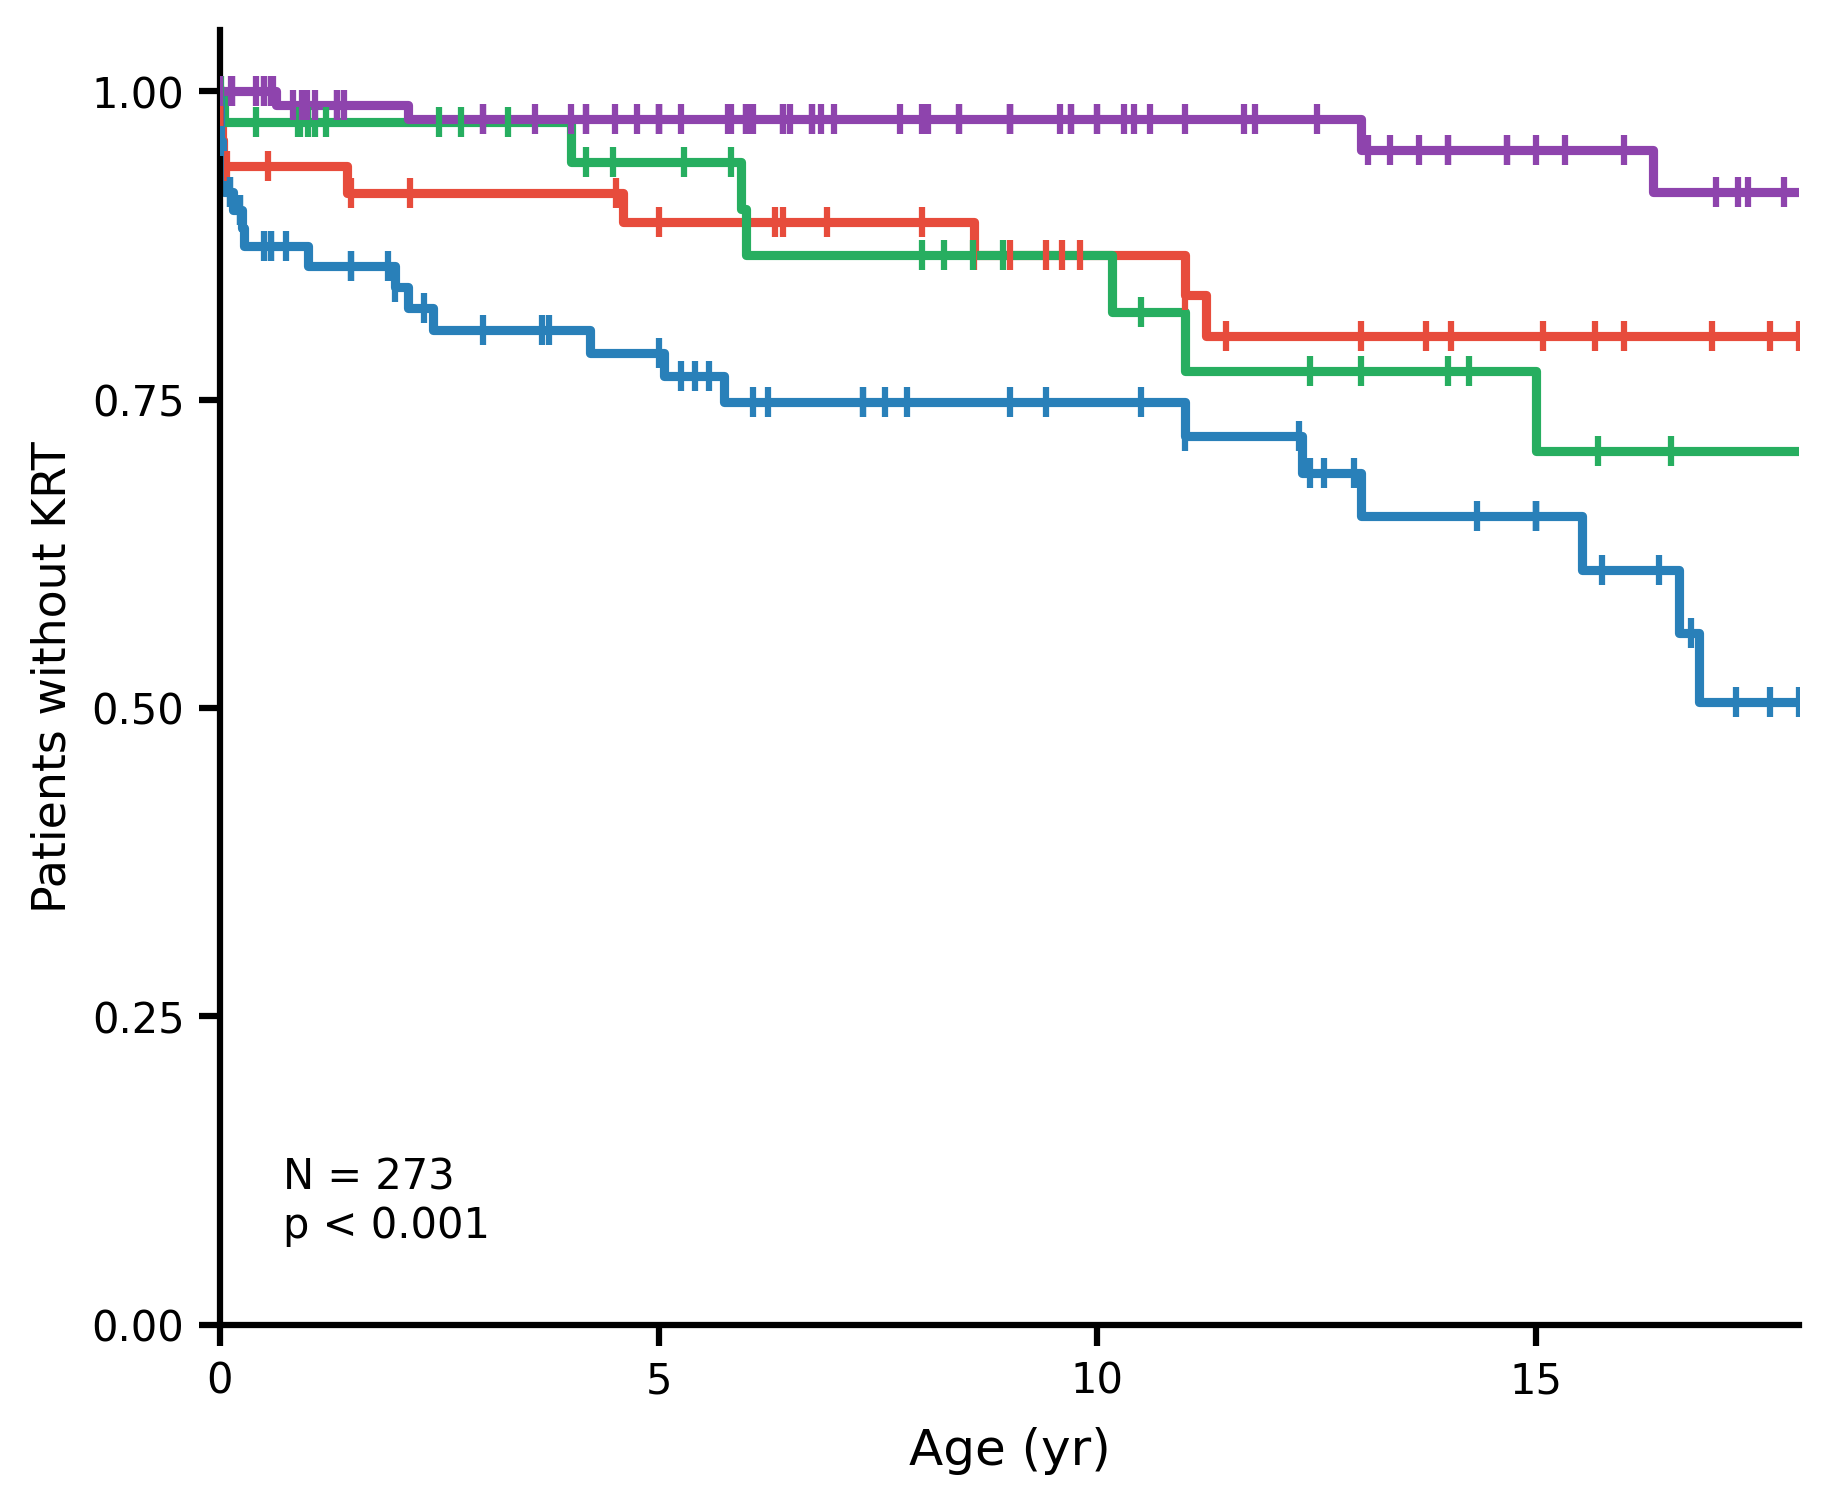


Pooled · KRT · n=273, events=54
Overall four-group log-rank: chi²=20.0187, p < 0.001
Saved: /content/PKHD1_pooled_four_class_figures/km_krt_pooled.png


,Group 1,Group 2,Log-rank p (raw),Holm-adjusted p
0,AA2625–4074,AA1838–2624,0.611597,0.611597
1,AA2625–4074,AA1–708,0.036001,0.180004
2,AA2625–4074,AA709–1837,0.063986,0.255944
3,AA1838–2624,AA1–708,0.127060,0.309968
4,AA1838–2624,AA709–1837,0.103323,0.309968
5,AA1–708,AA709–1837,0.000006,0.000038


Number at risk (actual KM-eligible patients):


,Group,N,Events,At risk 0y,At risk 5y,At risk 10y,At risk 15y
0,AA2625–4074,54,11,54,38,27,20
1,AA1838–2624,41,10,41,27,19,12
2,AA1–708,75,23,75,42,28,18
3,AA709–1837,103,10,103,76,48,31


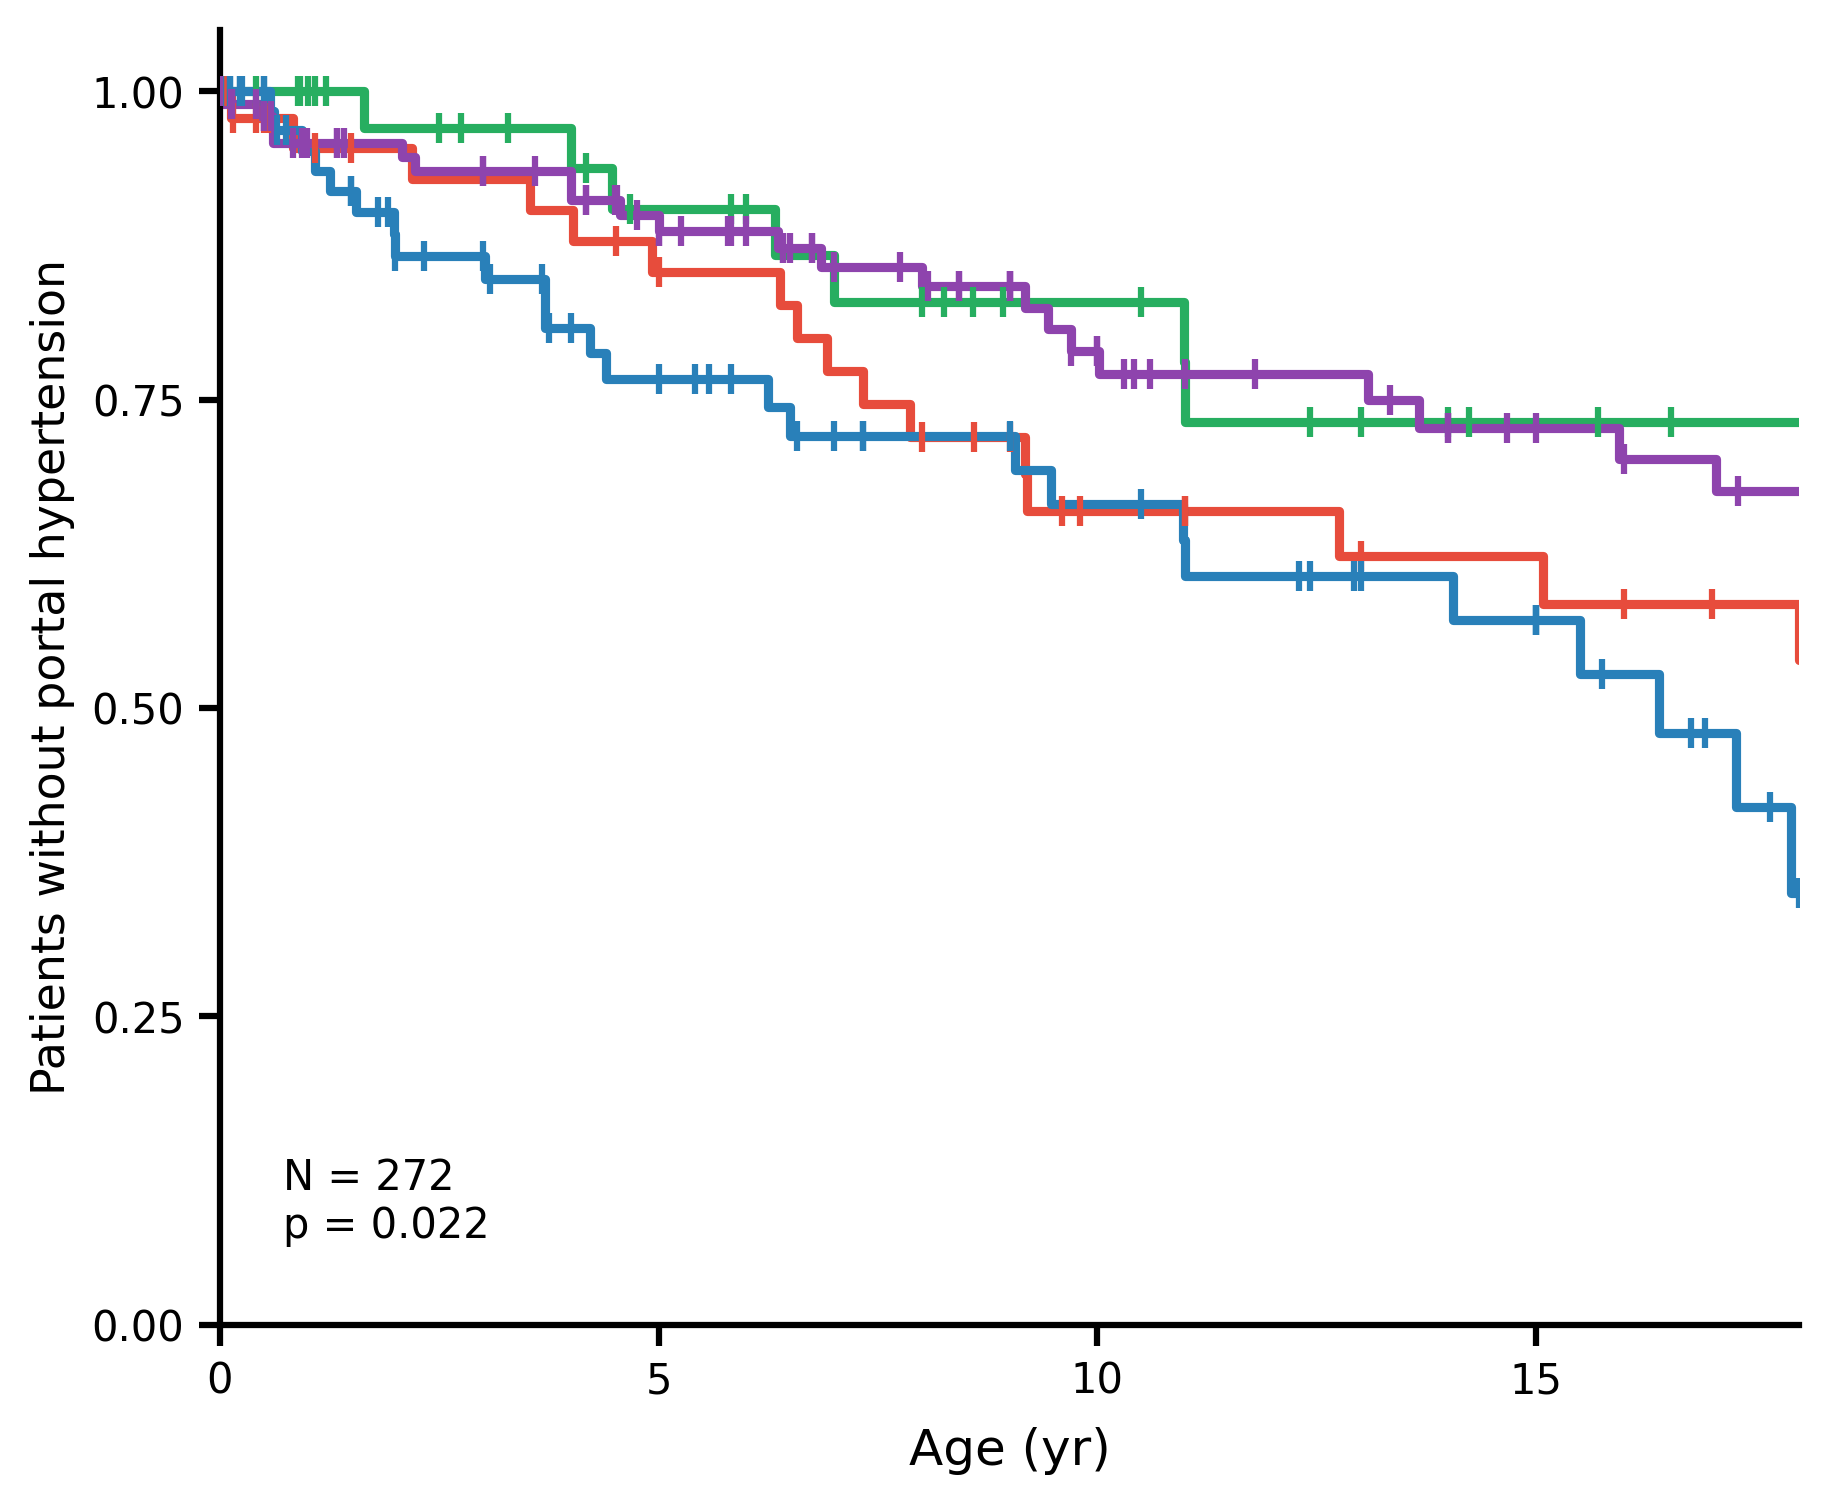


Pooled · Portal HTN · n=272, events=81
Overall four-group log-rank: chi²=9.6315, p = 0.022
Saved: /content/PKHD1_pooled_four_class_figures/km_portal_htn_pooled.png


,Group 1,Group 2,Log-rank p (raw),Holm-adjusted p
0,AA2625–4074,AA1838–2624,0.065071,0.260283
1,AA2625–4074,AA1–708,0.448844,0.897689
2,AA2625–4074,AA709–1837,0.073075,0.260283
3,AA1838–2624,AA1–708,0.032789,0.163945
4,AA1838–2624,AA709–1837,0.671088,0.897689
5,AA1–708,AA709–1837,0.010605,0.063628


Number at risk (actual KM-eligible patients):


,Group,N,Events,At risk 0y,At risk 5y,At risk 10y,At risk 15y
0,AA2625–4074,53,21,53,33,20,16
1,AA1838–2624,41,10,41,26,18,11
2,AA1–708,75,25,75,37,24,16
3,AA709–1837,103,25,103,71,44,30


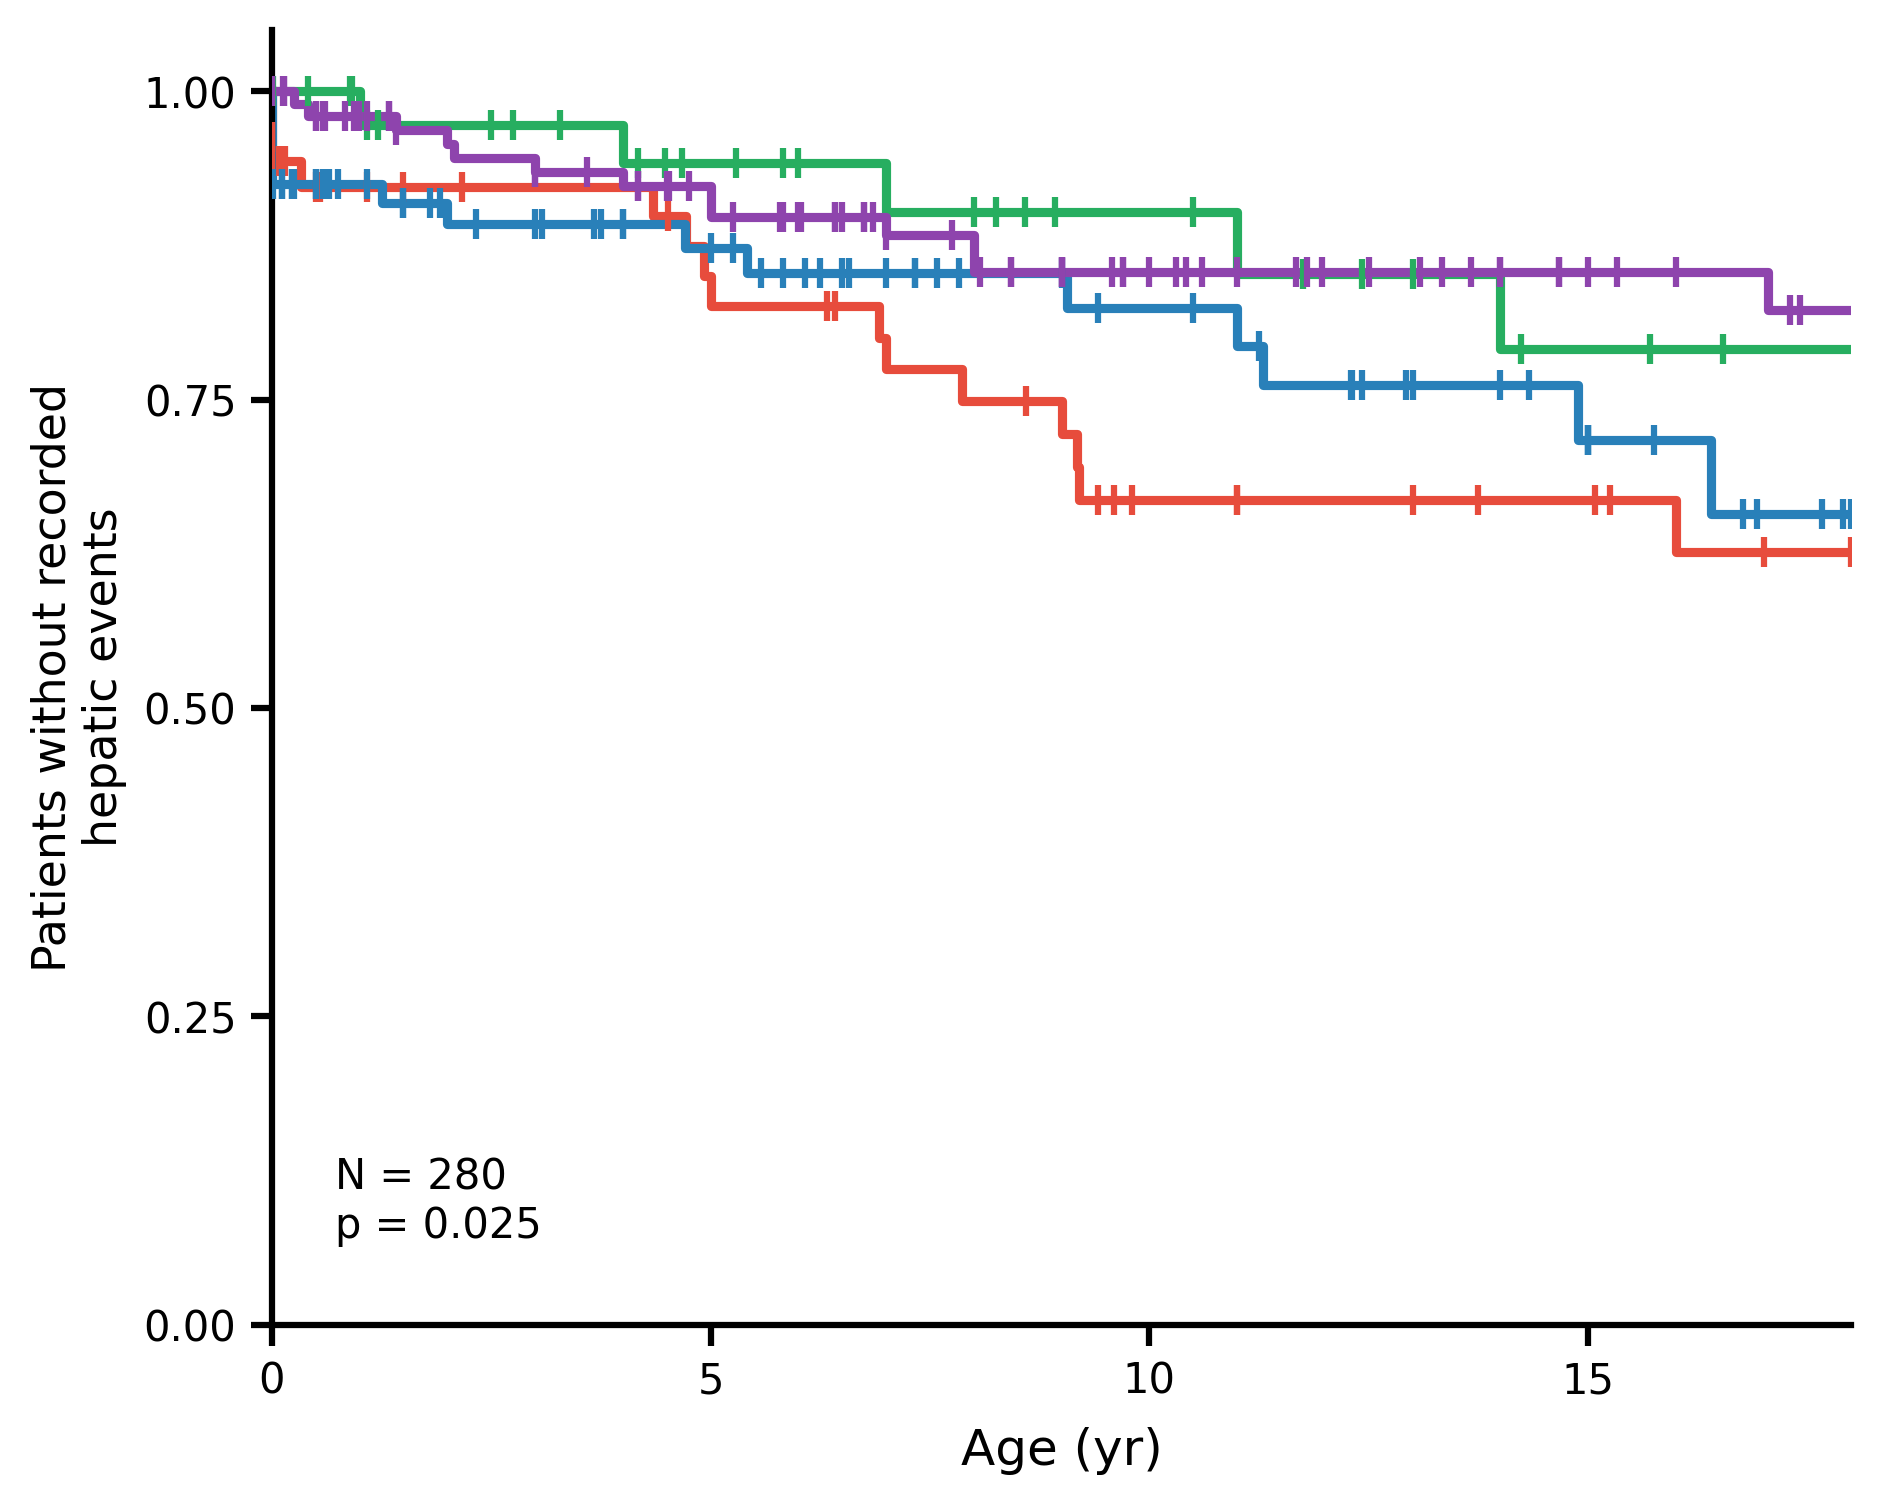


Pooled · Hepatic · n=280, events=62
Overall four-group log-rank: chi²=9.3882, p = 0.025
Saved: /content/PKHD1_pooled_four_class_figures/km_hepatic_pooled.png


,Group 1,Group 2,Log-rank p (raw),Holm-adjusted p
0,AA2625–4074,AA1838–2624,0.058404,0.292022
1,AA2625–4074,AA1–708,0.489511,0.979022
2,AA2625–4074,AA709–1837,0.005373,0.032237
3,AA1838–2624,AA1–708,0.246255,0.738764
4,AA1838–2624,AA709–1837,0.828387,0.979022
5,AA1–708,AA709–1837,0.060830,0.292022


Number at risk (actual KM-eligible patients):


,Group,N,Events,At risk 0y,At risk 5y,At risk 10y,At risk 15y
0,AA2625–4074,54,20,54,35,22,18
1,AA1838–2624,41,9,41,27,19,12
2,AA1–708,80,17,80,45,28,16
3,AA709–1837,105,16,105,74,47,31


Summary of overall four-class tests:


,endpoint,n,events,chi2,p
0,KRT,273,54,20.018723,0.000168
1,Portal HTN,272,81,9.631480,0.021973
2,Hepatic,280,62,9.388250,0.024550


In [14]:
plt.rcParams.update({
    'font.family':'DejaVu Sans',
    'font.size':11,
    'axes.linewidth':1.5,
    'axes.spines.top':False,
    'axes.spines.right':False,
    'xtick.major.width':1.5,
    'ytick.major.width':1.5,
    'xtick.major.size':5,
    'ytick.major.size':5,
    'figure.dpi':300,
    'figure.facecolor':'none',
    'axes.facecolor':'none',
})
TIMEPOINTS=[0,5,10,15]

def fmt_p(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'


def plot_four_classes(endpoint, ylabel, filename):
    data = SURVIVAL[endpoint]
    fig, ax = plt.subplots(figsize=(6.5,5.2))
    fig.patch.set_alpha(0)
    ax.patch.set_alpha(0)
    fig.subplots_adjust(left=0.16,right=0.97,top=0.96,bottom=0.13)

    for label in GROUP_ORDER:
        sub = data[data.group==label]
        if sub.empty: continue
        duration=sub.duration.to_numpy(dtype=float)
        event=sub.event.to_numpy(dtype=int)
        kmf=KaplanMeierFitter()
        kmf.fit(duration,event_observed=event,label=label)
        kmf.plot_survival_function(ax=ax,ci_show=False,
            color=COLORS[label],linewidth=2.2,label=label)
        t_cens = duration[event==0]
        if len(t_cens):
            p_cens=kmf.survival_function_at_times(t_cens).to_numpy()
            ax.scatter(t_cens,p_cens,marker='|',color=COLORS[label],
                       s=50,linewidth=1.5,zorder=5)

    overall=multivariate_logrank_test(data.duration,data.group,data.event)
    ax.text(0.04,0.06,f'N = {len(data)}\n{fmt_p(overall.p_value)}',
            transform=ax.transAxes,fontsize=10,va='bottom')
    if ax.get_legend():ax.get_legend().remove()
    ax.set_xlim(0,PLOT_END_YEAR)
    ax.set_ylim(0,1.05)
    ax.set_xlabel('Age (yr)',fontsize=12,labelpad=6)
    ax.set_ylabel(ylabel,fontsize=11)
    ax.set_xticks([0,5,10,15])
    ax.set_yticks([0,.25,.50,.75,1.00])
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x,_:f'{x:.2f}'))
    ax.tick_params(axis='both',labelsize=10)
    plot_path=OUTPUT_DIR/f'{filename}_{COHORT.lower()}.png'
    fig.savefig(plot_path,dpi=300,bbox_inches='tight',transparent=True)
    plt.show();plt.close(fig)

    # Single separate legend PNG in same style as existing notebook.
    legend_path=OUTPUT_DIR/'four_class_legend.png'
    if not legend_path.exists():
        fig_leg,ax_leg=plt.subplots(figsize=(4.0,1.6))
        fig_leg.patch.set_alpha(0);ax_leg.patch.set_alpha(0)
        ax_leg.axis('off')
        handles=[plt.Line2D([0],[0],color=COLORS[g],linewidth=2.5) for g in GROUP_ORDER]
        ax_leg.legend(handles,GROUP_ORDER,loc='center left',fontsize=9,
                      frameon=False,handlelength=2.0,labelspacing=0.7)
        fig_leg.savefig(legend_path,dpi=300,bbox_inches='tight',transparent=True)
        plt.close(fig_leg)

    print(f'\nPooled · {endpoint} · n={len(data)}, events={int(data.event.sum())}')
    print(f'Overall four-group log-rank: chi²={overall.test_statistic:.4f}, {fmt_p(overall.p_value)}')
    print('Saved:',plot_path)

    # Six pairwise comparisons, with Holm adjustment to guard against multiplicity.
    pairs=[]
    for g1,g2 in itertools.combinations(GROUP_ORDER,2):
        a,b=data[data.group==g1],data[data.group==g2]
        test=logrank_test(a.duration,b.duration,a.event,b.event)
        pairs.append((g1,g2,float(test.p_value)))
    ps=np.array([x[2] for x in pairs]); order=np.argsort(ps)
    adj=np.empty(len(ps)); k=len(ps)
    prev=0
    for rank,i in enumerate(order):
        prev=max(prev,min(1.,(k-rank)*ps[i])); adj[i]=prev
    pair_df=pd.DataFrame({'Group 1':[x[0] for x in pairs],
        'Group 2':[x[1] for x in pairs], 'Log-rank p (raw)':ps,
        'Holm-adjusted p':adj})
    display(pair_df)

    risk=[]
    for label in GROUP_ORDER:
        s=data[data.group==label]
        record={'Group':label,'N':len(s),'Events':int(s.event.sum())}
        for t in TIMEPOINTS:record[f'At risk {t}y']=int((s.duration>=t).sum())
        risk.append(record)
    risk_df=pd.DataFrame(risk)
    print('Number at risk (actual KM-eligible patients):')
    display(risk_df)
    return {'endpoint':endpoint,'n':len(data),'events':int(data.event.sum()),
            'chi2':float(overall.test_statistic),'p':float(overall.p_value)}, pair_df, risk_df

stats=[]; pair_tables=[]; risk_tables=[]
for endpoint,ylabel,fname in ENDPOINTS:
    result,pairs,risk=plot_four_classes(endpoint,ylabel,fname)
    stats.append(result)
    pairs.insert(0,'Endpoint',endpoint);pair_tables.append(pairs)
    risk.insert(0,'Endpoint',endpoint);risk_tables.append(risk)

stats_df=pd.DataFrame(stats)
print('Summary of overall four-class tests:')
display(stats_df)

# Cox model

In [15]:

# ================================================================
# PKHD1 | POOLED FOUR-FUNCTIONAL-CLASS COX REGRESSION
# Same patients, endpoints, and censoring as the pooled KM plots
# ================================================================

from lifelines import CoxPHFitter
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests
from itertools import combinations
from IPython.display import display
import numpy as np
import pandas as pd

REFERENCE = "AA709–1837"

# Uses GROUP_ORDER and SURVIVAL from the previous notebook cells
OTHER_GROUPS = [g for g in GROUP_ORDER if g != REFERENCE]
DUMMY = {g: f"class_{i}" for i, g in enumerate(OTHER_GROUPS, 1)}
COX_COLS = list(DUMMY.values())

assert REFERENCE in GROUP_ORDER
assert len(GROUP_ORDER) == 4

cox_results = []

def run_cox(endpoint, stratify=False):

    df = SURVIVAL[endpoint][
        ["duration", "event", "group", "cohort"]
    ].copy()

    df["duration"] = df["duration"].astype(float)
    df["event"] = df["event"].astype(int)

    # Reference group has zeros for all three indicators
    for group, col in DUMMY.items():
        df[col] = (df["group"] == group).astype(int)

    model_cols = ["duration", "event"] + COX_COLS
    if stratify:
        model_cols += ["cohort"]

    cph = CoxPHFitter()
    cph.fit(
        df[model_cols],
        duration_col="duration",
        event_col="event",
        strata=["cohort"] if stratify else None,
        show_progress=False
    )

    beta = cph.params_.reindex(COX_COLS).to_numpy()
    covariance = cph.variance_matrix_.loc[
        COX_COLS, COX_COLS
    ].to_numpy()

    z_critical = norm.ppf(0.975)

    def contrast(group1, group2):
        """HR for group1 relative to group2."""
        v = np.zeros(len(COX_COLS))

        if group1 != REFERENCE:
            v[COX_COLS.index(DUMMY[group1])] += 1

        if group2 != REFERENCE:
            v[COX_COLS.index(DUMMY[group2])] -= 1

        log_hr = float(v @ beta)
        se = float(np.sqrt(v @ covariance @ v))
        z = log_hr / se

        return {
            "Group 1": group1,
            "Group 2 (reference)": group2,
            "HR": np.exp(log_hr),
            "95% CI lower": np.exp(log_hr - z_critical * se),
            "95% CI upper": np.exp(log_hr + z_critical * se),
            "p": 2 * norm.sf(abs(z))
        }

    label = "Cohort-stratified" if stratify else "Unadjusted"

    print("\n" + "=" * 70)
    print(f"{endpoint.upper()} | {label} Cox regression")
    print(f"N = {len(df)} | Events = {df['event'].sum()}")
    print("=" * 70)

    # 1. Three HRs compared against AA709–1837
    primary = pd.DataFrame([
        contrast(g, REFERENCE) for g in OTHER_GROUPS
    ])

    print(f"\nHazard ratios relative to {REFERENCE}:")
    display(primary.round(5))

    # 2. All six pairwise HRs
    pairwise = pd.DataFrame([
        contrast(a, b)
        for a, b in combinations(GROUP_ORDER, 2)
    ])

    pairwise["Holm-adjusted p"] = multipletests(
        pairwise["p"], method="holm"
    )[1]

    print("\nAll six pairwise comparisons:")
    display(pairwise.round(5))

    # 3. Export tables
    suffix = "stratified" if stratify else "unadjusted"
    fname = endpoint.lower().replace(" ", "_")

    primary.to_csv(
        OUTPUT_DIR / f"cox_{fname}_{suffix}_reference.csv",
        index=False
    )

    pairwise.to_csv(
        OUTPUT_DIR / f"cox_{fname}_{suffix}_pairwise.csv",
        index=False
    )

    primary["Endpoint"] = endpoint
    primary["Model"] = label
    cox_results.append(primary)

    return cph, primary, pairwise


# ================================================================
# PRIMARY: UNADJUSTED POOLED COX REGRESSION
# ================================================================

cox_models = {}

for endpoint in ["KRT", "Portal HTN", "Hepatic"]:
    model, primary, pairwise = run_cox(
        endpoint, stratify=False
    )
    cox_models[endpoint] = model


# ================================================================
# SECONDARY: STRATIFY BASELINE HAZARDS BY SOURCE COHORT
# Allows Burgmaier and NephVar different baseline hazards
# ================================================================

cox_stratified_models = {}

for endpoint in ["KRT", "Portal HTN", "Hepatic"]:
    model, primary, pairwise = run_cox(
        endpoint, stratify=True
    )
    cox_stratified_models[endpoint] = model


# ================================================================
# COMBINED SUMMARY
# ================================================================

cox_summary = pd.concat(cox_results, ignore_index=True)

print("\nFINAL HAZARD RATIO SUMMARY")
display(cox_summary.round(5))

cox_summary.to_csv(
    OUTPUT_DIR / "pooled_four_class_cox_summary.csv",
    index=False
)

print("\nAll Cox regression results saved to:", OUTPUT_DIR)



KRT | Unadjusted Cox regression
N = 273 | Events = 54

Hazard ratios relative to AA709–1837:


,Group 1,Group 2 (reference),HR,95% CI lower,95% CI upper,p
0,AA2625–4074,AA709–1837,2.01946,0.85585,4.76510,0.10859
1,AA1838–2624,AA709–1837,2.22410,0.91956,5.37928,0.07608
2,AA1–708,AA709–1837,4.70583,2.22365,9.95878,0.00005



All six pairwise comparisons:


,Group 1,Group 2 (reference),HR,95% CI lower,95% CI upper,p,Holm-adjusted p
0,AA2625–4074,AA1838–2624,0.90799,0.38106,2.16358,0.82753,0.82753
1,AA2625–4074,AA1–708,0.42914,0.20652,0.89173,0.02339,0.11694
2,AA2625–4074,AA709–1837,2.01946,0.85585,4.76510,0.10859,0.22825
3,AA1838–2624,AA1–708,0.47263,0.22037,1.01366,0.05422,0.21686
4,AA1838–2624,AA709–1837,2.22410,0.91956,5.37928,0.07608,0.22825
5,AA1–708,AA709–1837,4.70583,2.22365,9.95878,0.00005,0.00031



PORTAL HTN | Unadjusted Cox regression
N = 272 | Events = 81

Hazard ratios relative to AA709–1837:


,Group 1,Group 2 (reference),HR,95% CI lower,95% CI upper,p
0,AA2625–4074,AA709–1837,1.69972,0.95098,3.03796,0.07340
1,AA1838–2624,AA709–1837,0.87740,0.41609,1.85012,0.73113
2,AA1–708,AA709–1837,2.04693,1.16885,3.58466,0.01222


... (17 outputs left out)

,Group 1,Group 2 (reference),HR,95% CI lower,95% CI upper,p,Holm-adjusted p
0,AA2625–4074,AA1838–2624,1.95150,0.86616,4.39684,0.10669,0.42675
1,AA2625–4074,AA1–708,1.25377,0.63405,2.47919,0.51560,1.00000
2,AA2625–4074,AA709–1837,2.43595,1.25688,4.72110,0.00836,0.05016
3,AA1838–2624,AA1–708,0.64246,0.27586,1.49628,0.30502,0.91506
4,AA1838–2624,AA709–1837,1.24825,0.54052,2.88264,0.60358,1.00000
5,AA1–708,AA709–1837,1.94290,0.96015,3.93154,0.06476,0.32381



FINAL HAZARD RATIO SUMMARY


,Group 1,Group 2 (reference),HR,95% CI lower,95% CI upper,p,Endpoint,Model
0,AA2625–4074,AA709–1837,2.01946,0.85585,4.76510,0.10859,KRT,Unadjusted
1,AA1838–2624,AA709–1837,2.22410,0.91956,5.37928,0.07608,KRT,Unadjusted
2,AA1–708,AA709–1837,4.70583,2.22365,9.95878,0.00005,KRT,Unadjusted
3,AA2625–4074,AA709–1837,1.69972,0.95098,3.03796,0.07340,Portal HTN,Unadjusted
4,AA1838–2624,AA709–1837,0.87740,0.41609,1.85012,0.73113,Portal HTN,Unadjusted
5,AA1–708,AA709–1837,2.04693,1.16885,3.58466,0.01222,Portal HTN,Unadjusted
6,AA2625–4074,AA709–1837,2.50885,1.29685,4.85355,0.00629,Hepatic,Unadjusted
7,AA1838–2624,AA709–1837,1.16570,0.50570,2.68707,0.71897,Hepatic,Unadjusted
8,AA1–708,AA709–1837,1.93702,0.97150,3.86214,0.06040,Hepatic,Unadjusted
9,AA2625–4074,AA709–1837,2.10595,0.89084,4.97849,0.08976,KRT,Cohort-stratified



All Cox regression results saved to: /content/PKHD1_pooled_four_class_figures


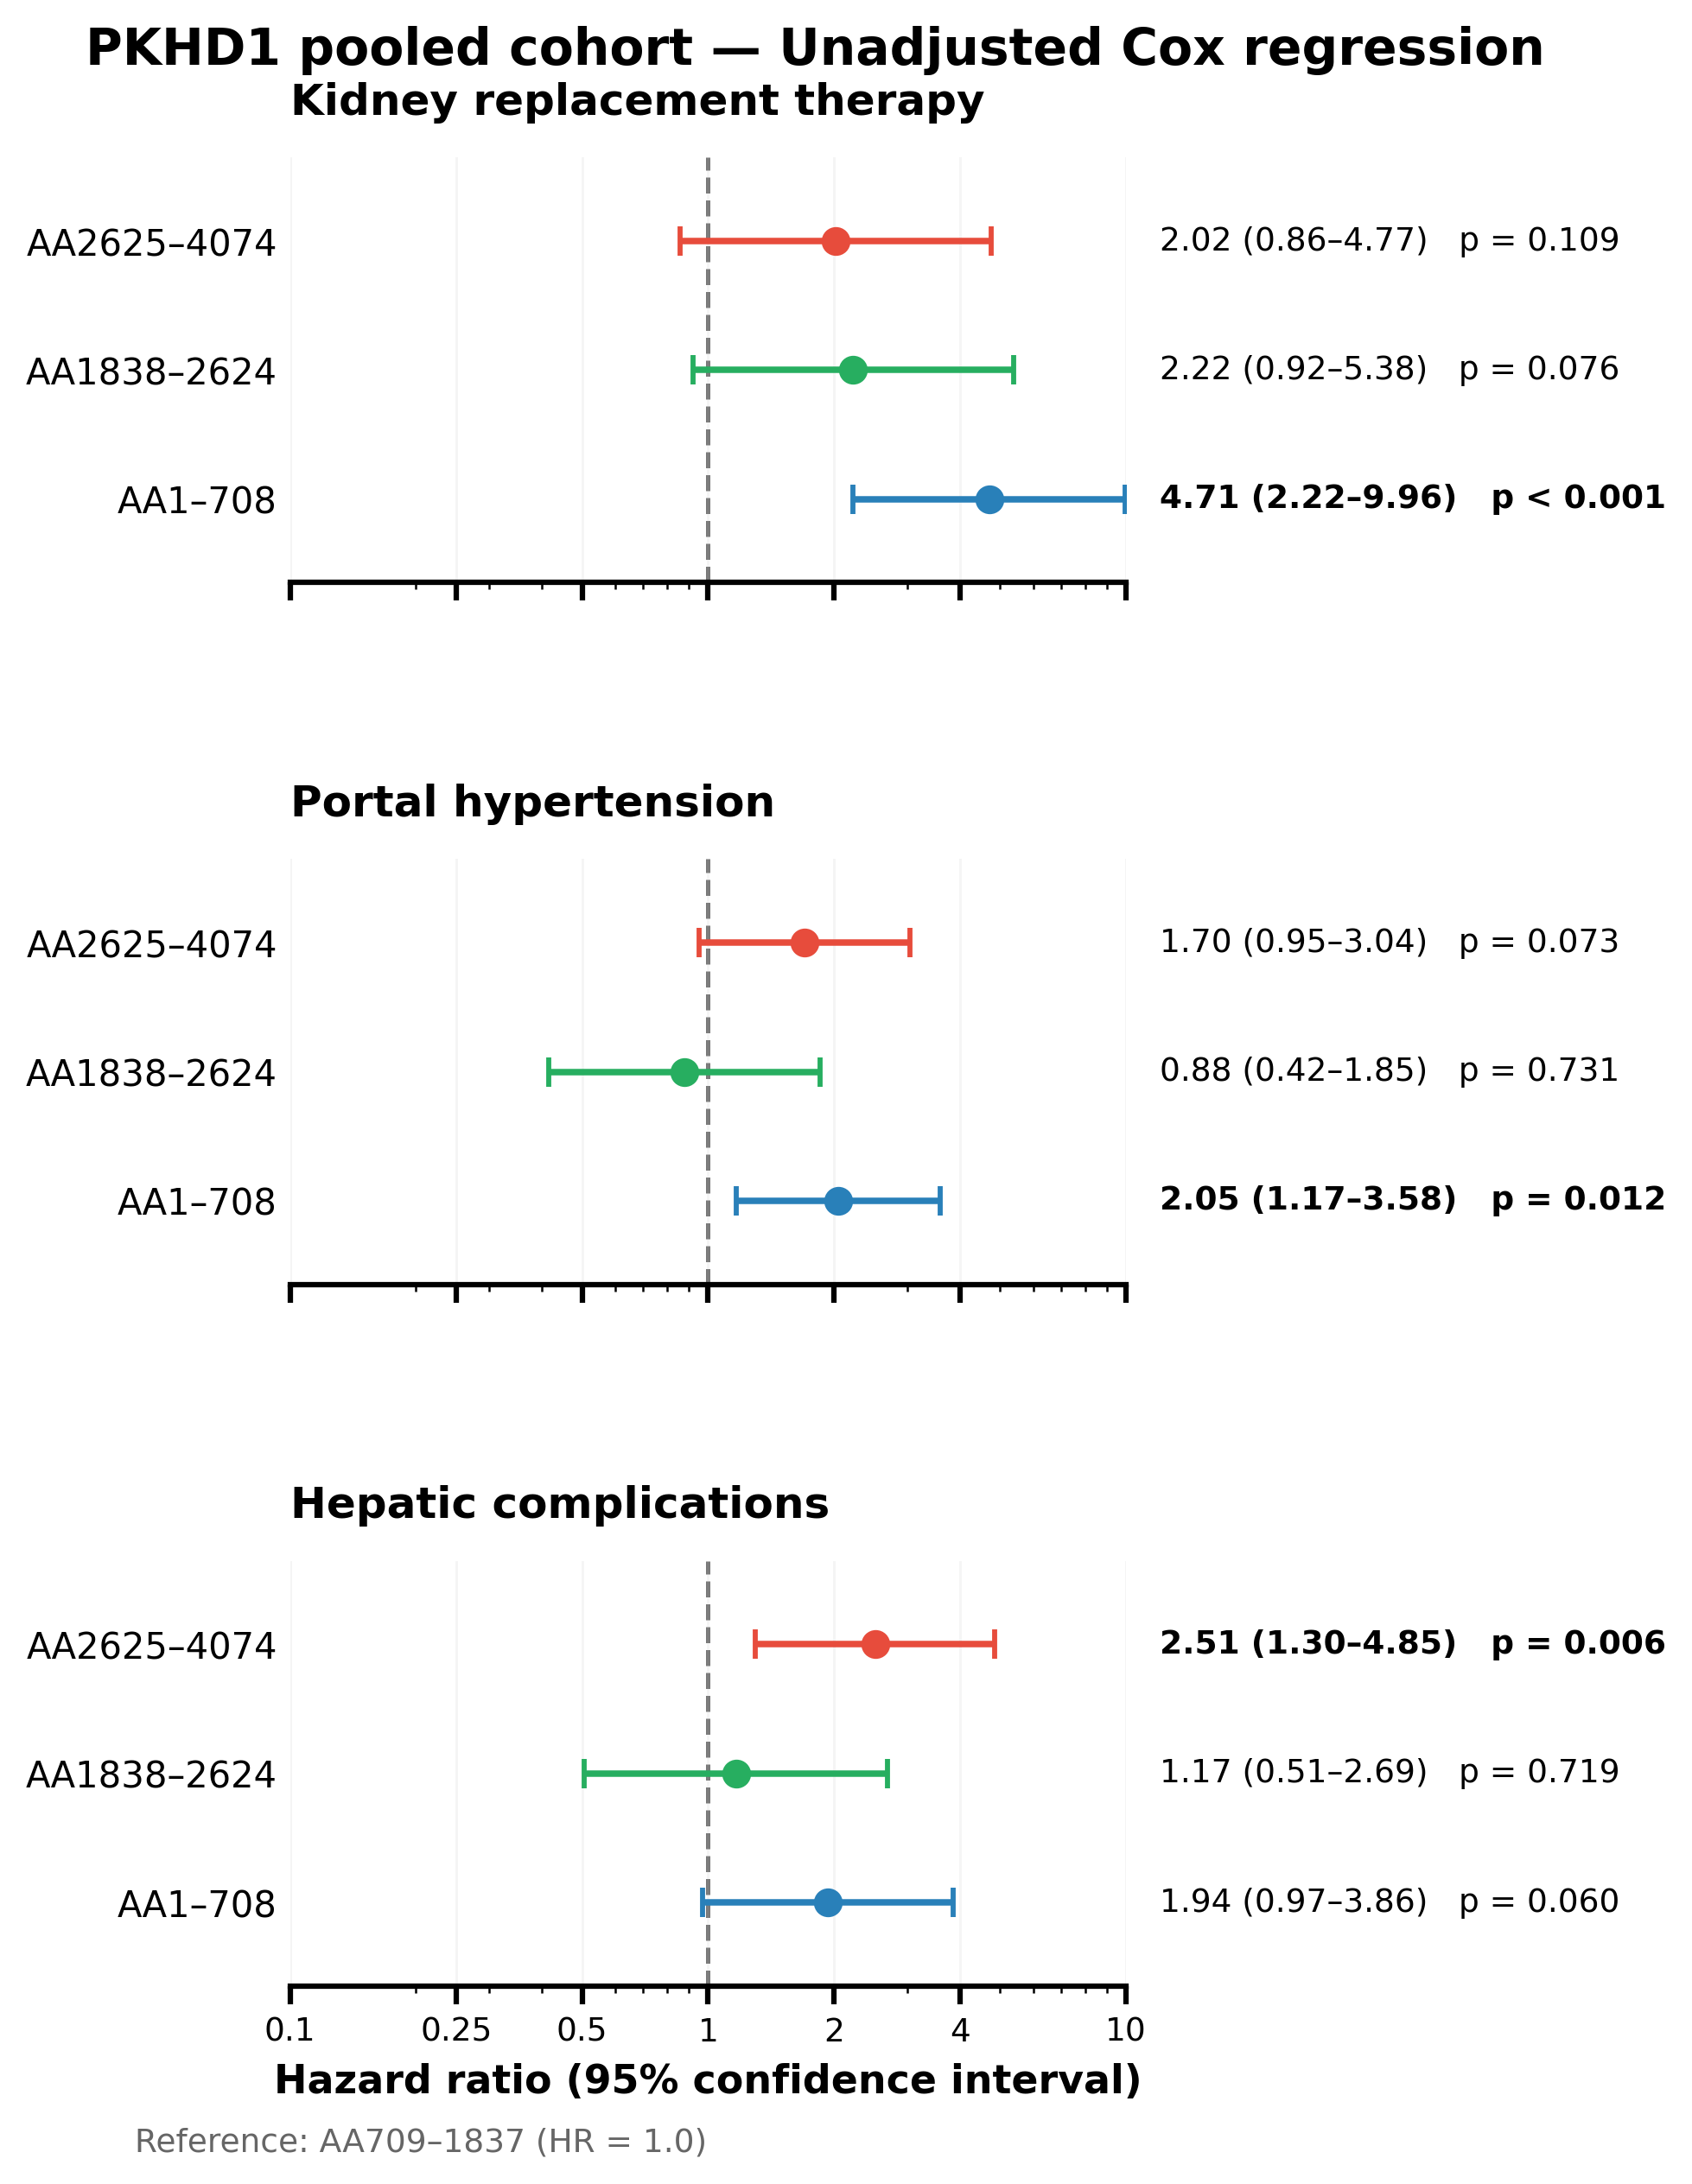

Saved: /content/PKHD1_pooled_four_class_figures/cox_forest_pooled_unadjusted.png


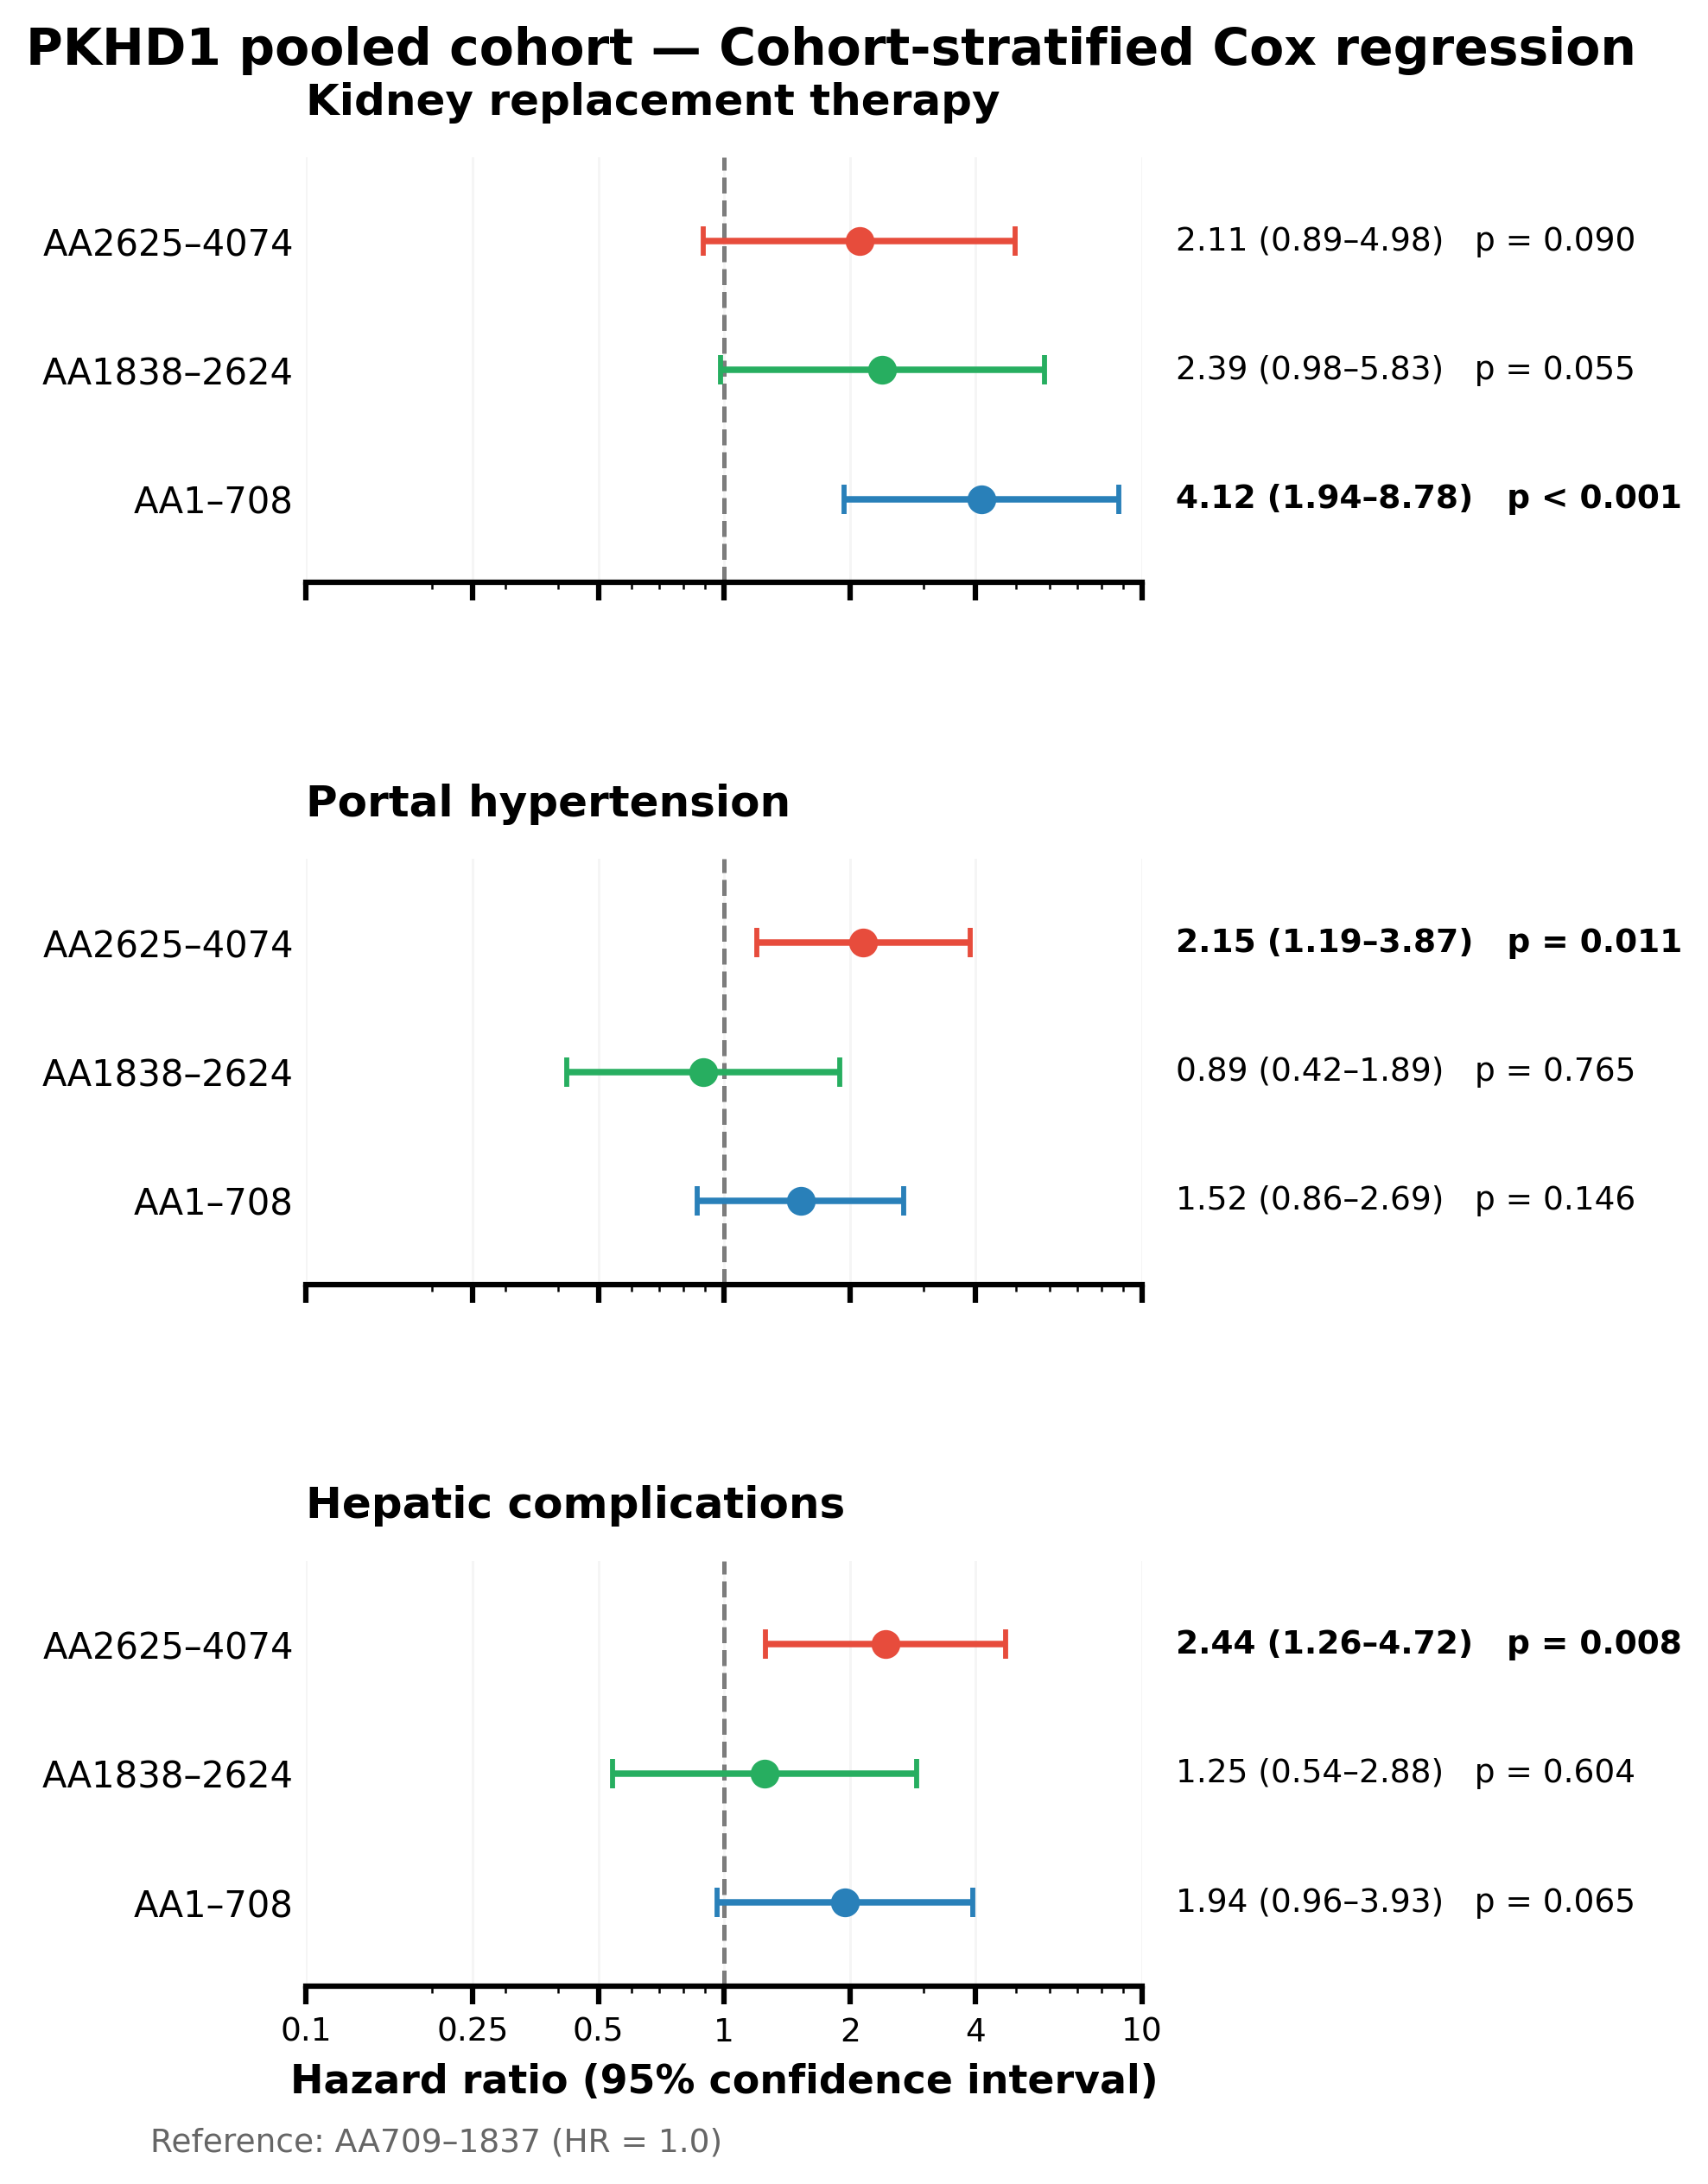

Saved: /content/PKHD1_pooled_four_class_figures/cox_forest_pooled_cohort_stratified.png


In [16]:

# ============================================================
# PKHD1 POOLED COHORT — COX HAZARD RATIO FOREST PLOTS
# Four functional classes | Burgmaier color scheme
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Uses cox_summary generated by the previous Cox regression cell.

OUT = Path("/content/PKHD1_pooled_four_class_figures")
OUT.mkdir(parents=True, exist_ok=True)

COLORS = {
    "AA2625–4074": "#e74c3c",   # Red
    "AA1838–2624": "#27ae60",   # Green
    "AA1–708": "#2980b9",      # Blue
    "AA709–1837": "#8e44ad",   # Purple (reference)
}

REFERENCE = "AA709–1837"

GROUPS = [
    "AA2625–4074",
    "AA1838–2624",
    "AA1–708",
]

ENDPOINTS = ["KRT", "Portal HTN", "Hepatic"]

ENDPOINT_LABELS = {
    "KRT": "Kidney replacement therapy",
    "Portal HTN": "Portal hypertension",
    "Hepatic": "Hepatic complications",
}

def format_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def plot_cox_forest(model="Unadjusted"):

    data = cox_summary[
        cox_summary["Model"] == model
    ].copy()

    fig, axes = plt.subplots(
        3, 1,
        figsize=(7.5, 8.5),
        sharex=True,
        gridspec_kw={"hspace": 0.65}
    )

    for ax, endpoint in zip(axes, ENDPOINTS):

        df = data[
            data["Endpoint"] == endpoint
        ].set_index("Group 1")

        ax.axvline(
            1, color="#777777",
            linestyle="--", linewidth=1.2,
            zorder=0
        )

        positions = np.arange(len(GROUPS))[::-1]

        for y, group in zip(positions, GROUPS):

            r = df.loc[group]

            hr = float(r["HR"])
            low = float(r["95% CI lower"])
            high = float(r["95% CI upper"])
            p = float(r["p"])

            ax.errorbar(
                hr, y,
                xerr=[[hr - low], [high - hr]],
                fmt="o",
                color=COLORS[group],
                ecolor=COLORS[group],
                markersize=7,
                elinewidth=1.8,
                capsize=4,
                capthick=1.4,
                zorder=3
            )

            # HR, CI, p-value shown in a separate
            # right-hand text column.
            annotation = (
                f"{hr:.2f} "
                f"({low:.2f}–{high:.2f})"
                f"   {format_p(p)}"
            )

            ax.text(
                1.04, y, annotation,
                transform=ax.get_yaxis_transform(),
                va="center", ha="left",
                fontsize=9,
                fontweight="bold" if p < 0.05 else "normal",
                clip_on=False
            )

        ax.set_yticks(positions)
        ax.set_yticklabels(GROUPS, fontsize=10)

        ax.set_title(
            ENDPOINT_LABELS[endpoint],
            loc="left",
            fontweight="bold",
            fontsize=12,
            pad=12
        )

        ax.set_xscale("log")
        ax.set_xlim(0.1, 10)
        ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 4, 10])
        ax.set_xticklabels(
            ["0.1", "0.25", "0.5", "1", "2", "4", "10"]
        )

        ax.set_ylim(-0.65, 2.65)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)

        ax.tick_params(axis="y", length=0)
        ax.tick_params(axis="x", labelsize=9)
        ax.grid(
            axis="x",
            alpha=0.12,
            linewidth=0.7
        )

    axes[-1].set_xlabel(
        "Hazard ratio (95% confidence interval)",
        fontsize=11,
        fontweight="bold"
    )

    fig.suptitle(
        f"PKHD1 pooled cohort — {model} Cox regression",
        fontsize=14,
        fontweight="bold",
        y=0.99
    )

    fig.text(
        0.15, 0.025,
        f"Reference: {REFERENCE} (HR = 1.0)",
        fontsize=9,
        color="#666666"
    )

    fig.subplots_adjust(
        left=0.23,
        right=0.66,
        top=0.93,
        bottom=0.10
    )

    filename = (
        "cox_forest_pooled_"
        + model.lower().replace("-", "_")
        .replace(" ", "_")
    )

    fig.savefig(
        OUT / f"{filename}.png",
        dpi=300,
        transparent=True,
        bbox_inches="tight"
    )

    fig.savefig(
        OUT / f"{filename}.pdf",
        transparent=True,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", OUT / f"{filename}.png")


# ------------------------------------------------------------
# Generate both forest plots
# ------------------------------------------------------------

plot_cox_forest("Unadjusted")
plot_cox_forest("Cohort-stratified")
